# Benchmarking Comparison

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 26.01.2025
- Date of Last Modification: 12.01.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the nichejepa conda environment, installable from ```../../envs/nichejepa.yaml```.

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import os
import re
import warnings
from collections import OrderedDict

import anndata as ad
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

### 1.4 Run Notebook Setup

In [5]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [6]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [7]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [8]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [9]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)

## 2. Data Visualization

### 2.1 Niche Identification

#### 2.1.1 chl59-8b_1p (NanoString CosMx Human NSCLC)

In [ ]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
niche_key = 'niche'
batch_key = 'batch'
spot_sizes = [80 * 0.18] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.18 # conversion rate from https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/SMI-ReadMe.html

In [ ]:
adata.obs[niche_key].unique()

In [ ]:
# Plot ground truth niches

# Label niches (based on NicheCompass reproducibility repo)
label2niche = {
    '0': '1- Tumor (stroma border)',
    '2': '2- Tumor interior',
    '5': '3- Tumor (neutrophil border)',
    '7': '4- Tumor interior',
    '11': '5- Infiltrated tumor',
    '3': '6- Tumor-infiltrating neutrophils',
    '4': '7- Neutrophil expansion',
    '1': '8- Stroma',
    '6': '9- Plasmablast rich stroma',
    '9': '10- Lymphoid rich stroma',
    '8': '11- Lymphoid aggregates',
    '10': '12- Macrophage rich stroma'
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_groundtruth_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

#### 2.1.2 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [ ]:
# Define dataset params
dataset_name = 'chr78-11b_1p'
batches = ['CM007',
           'CM008',
           'CM009',
           'CM011',
           'CM013',
           'CM015',
           'CM016',
           'CM017',
           'CM018',
           'CM019',
           'CM020']
niche_key = 'broad_anatomy'
batch_key = 'batch'
spot_sizes = [240 * 0.093] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.093 # conversion rate from Valentina

In [ ]:
# Combine regions
adata.obs[niche_key] = adata.obs[niche_key].apply(lambda x: x.replace('Urogenital Sinus', 'UrogenitalSinus'))

In [ ]:
# Plot ground truth niches

# Label niches
label2niche = {
    '0': 'Adrenal',
    '1': 'Cervix',
    '2': 'Ducts',
    '3': 'Epididymis',
    '4': 'Epoophron',
    '5': 'External Genitalia',
    '6': 'FallopianTube',
    '7': 'Genital Tubercle',
    '8': 'Gonad',
    '9': 'LabioScrotal Swelling',
    '10': 'LowerTract',
    '11': 'Nephros',
    '12': 'Testis',
    '13': 'Unassigned',
    '14': 'UpperVagina',
    '15': 'Urogenital Sinus',
    '16': 'UrogenitalSinus',
    '17': 'Uterus',
    '18': 'VaginalPlate',
    '19': 'Vas Deferens',
    '20': 'Background', # < 100 cells
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_groundtruth_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

#### 2.1.3 xhs49-1b_1p (Xenium Human Melanoma)

In [ ]:
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
spot_size = 20

In [ ]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Xenium_Prime_Human_Skin_FFPE_outs.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs['niche_name'].isna()]

In [ ]:
adata.obs['niche_name'].value_counts()

In [ ]:
# Plot ground truth niches

# Label niches
label2niche = {
    '0': 'Epidemis',
    '1': 'Superficial dermis',
    '2': 'Melanoma+infiltrate',
    '3': 'Melanoma',
    '4': 'Immune infiltrate Thi',
    '5': 'Immune infiltrate Mac hi',
    '6': 'Macrophage_fat_region',
    '7': 'Melanoma+blood vessels'
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_groundtruth_niches.svg'
sc.pl.spatial(adata,
              color=niche_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

#### 2.1.4 xhs1000-39b_1p (Xenium Human Skin - Eczema)

In [25]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
niche_key = 'niche_type'
#batch_key = 'sample'
batch_key = 'batch'
spot_sizes = [20] * len(batches)
folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'

In [54]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial']

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [55]:
adata_emb = sc.read_h5ad(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

/tmp/ipykernel_2253437/3197656281.py:40: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


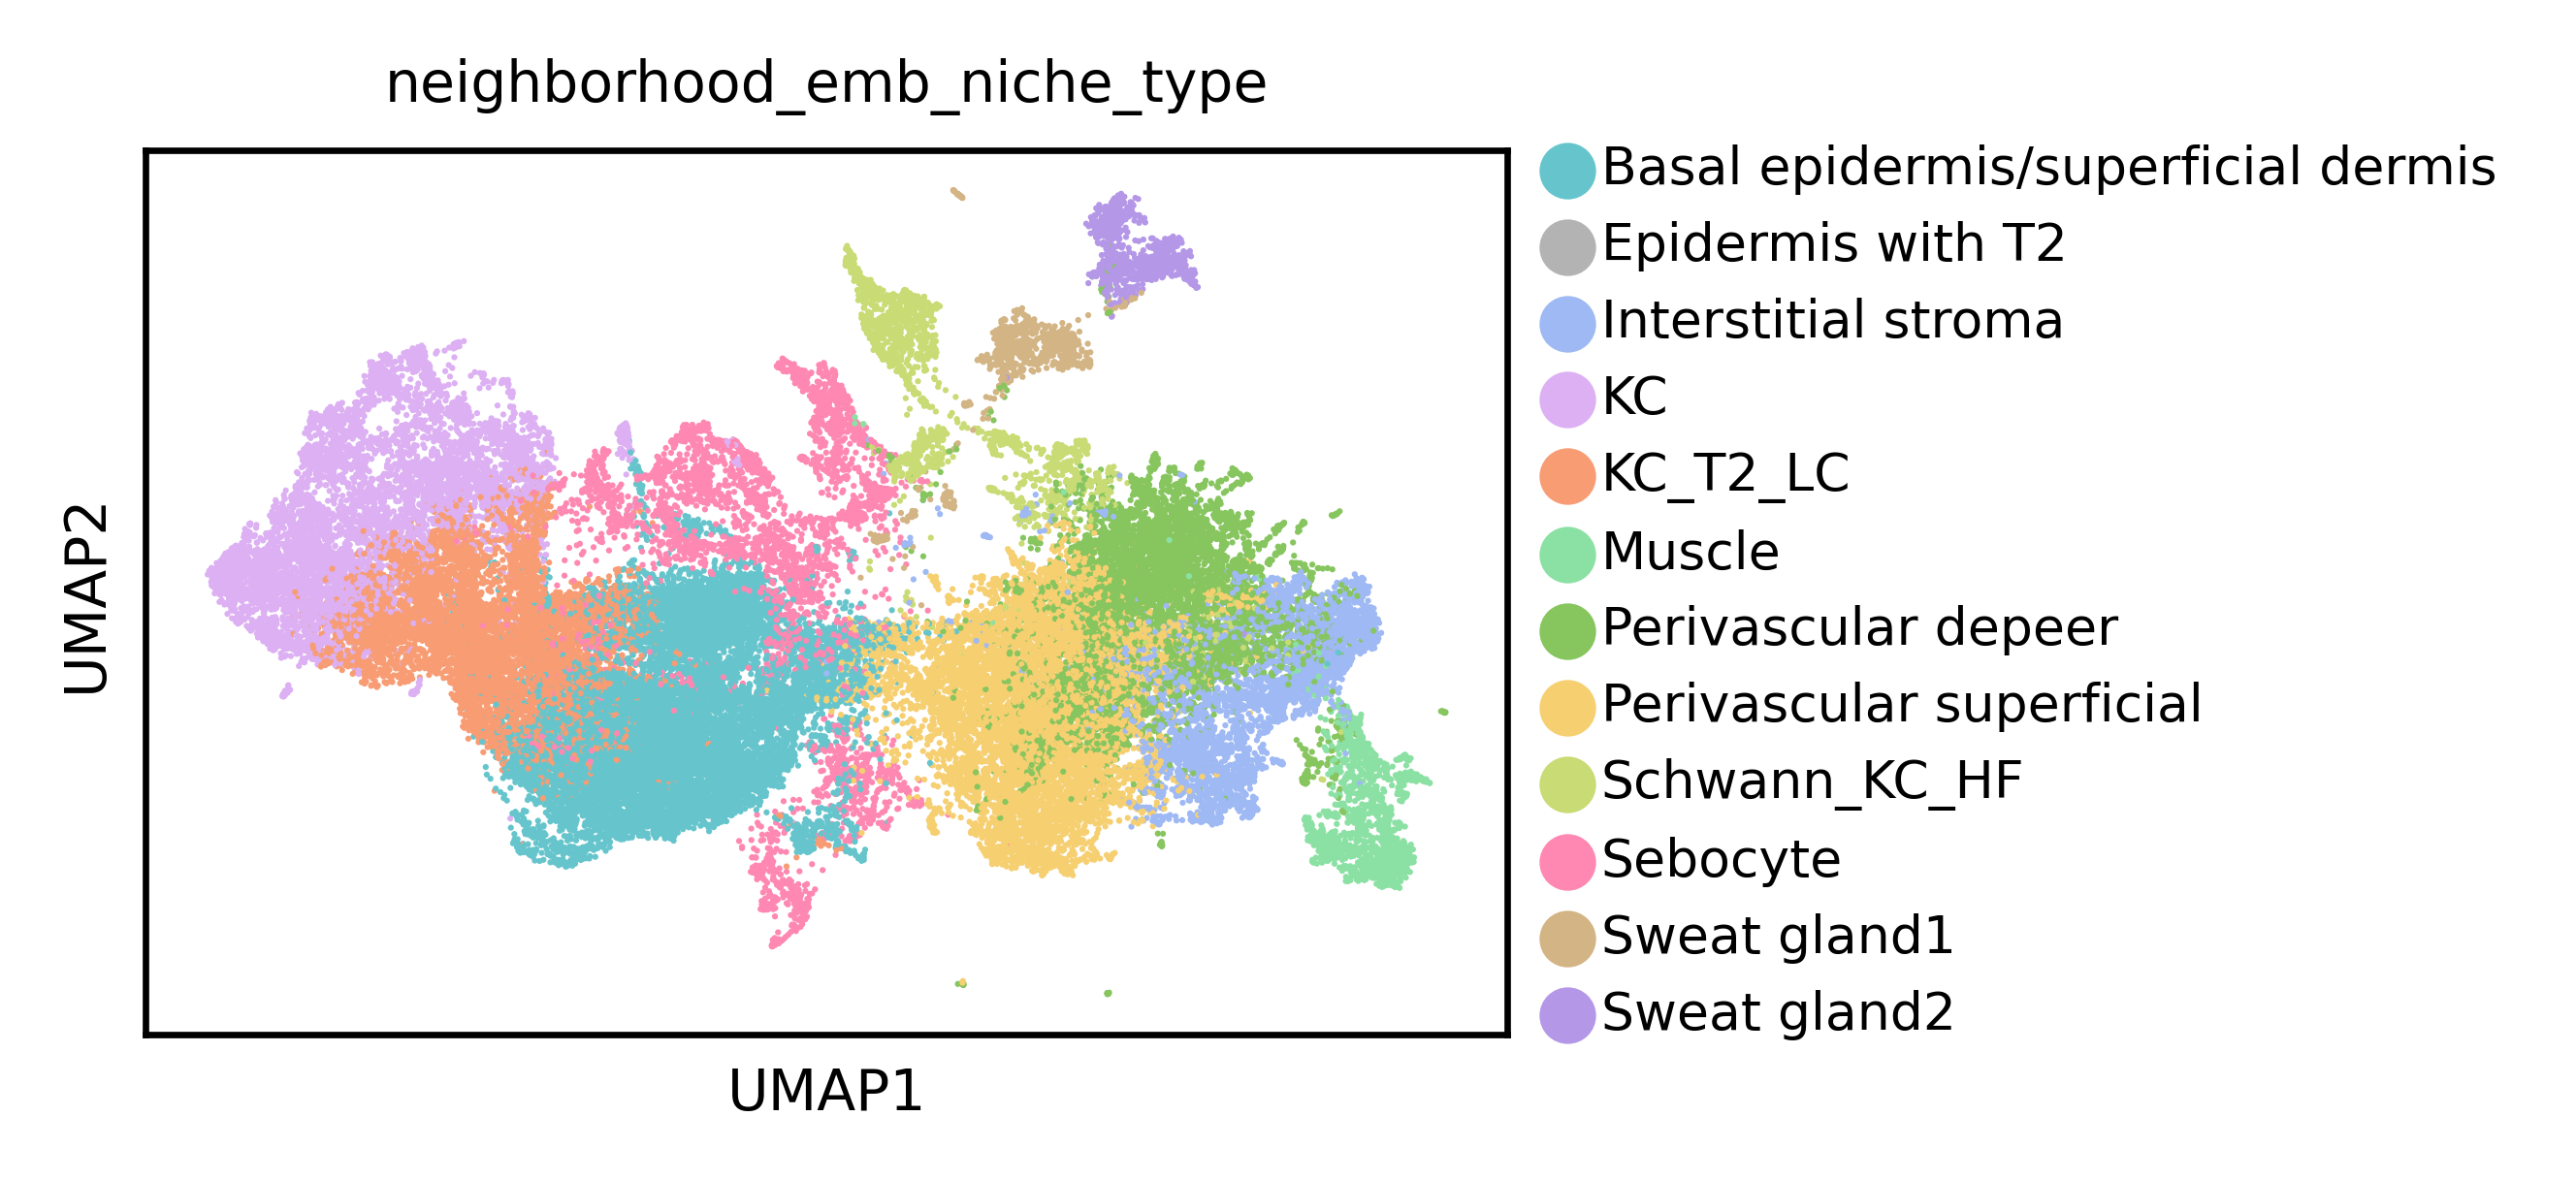

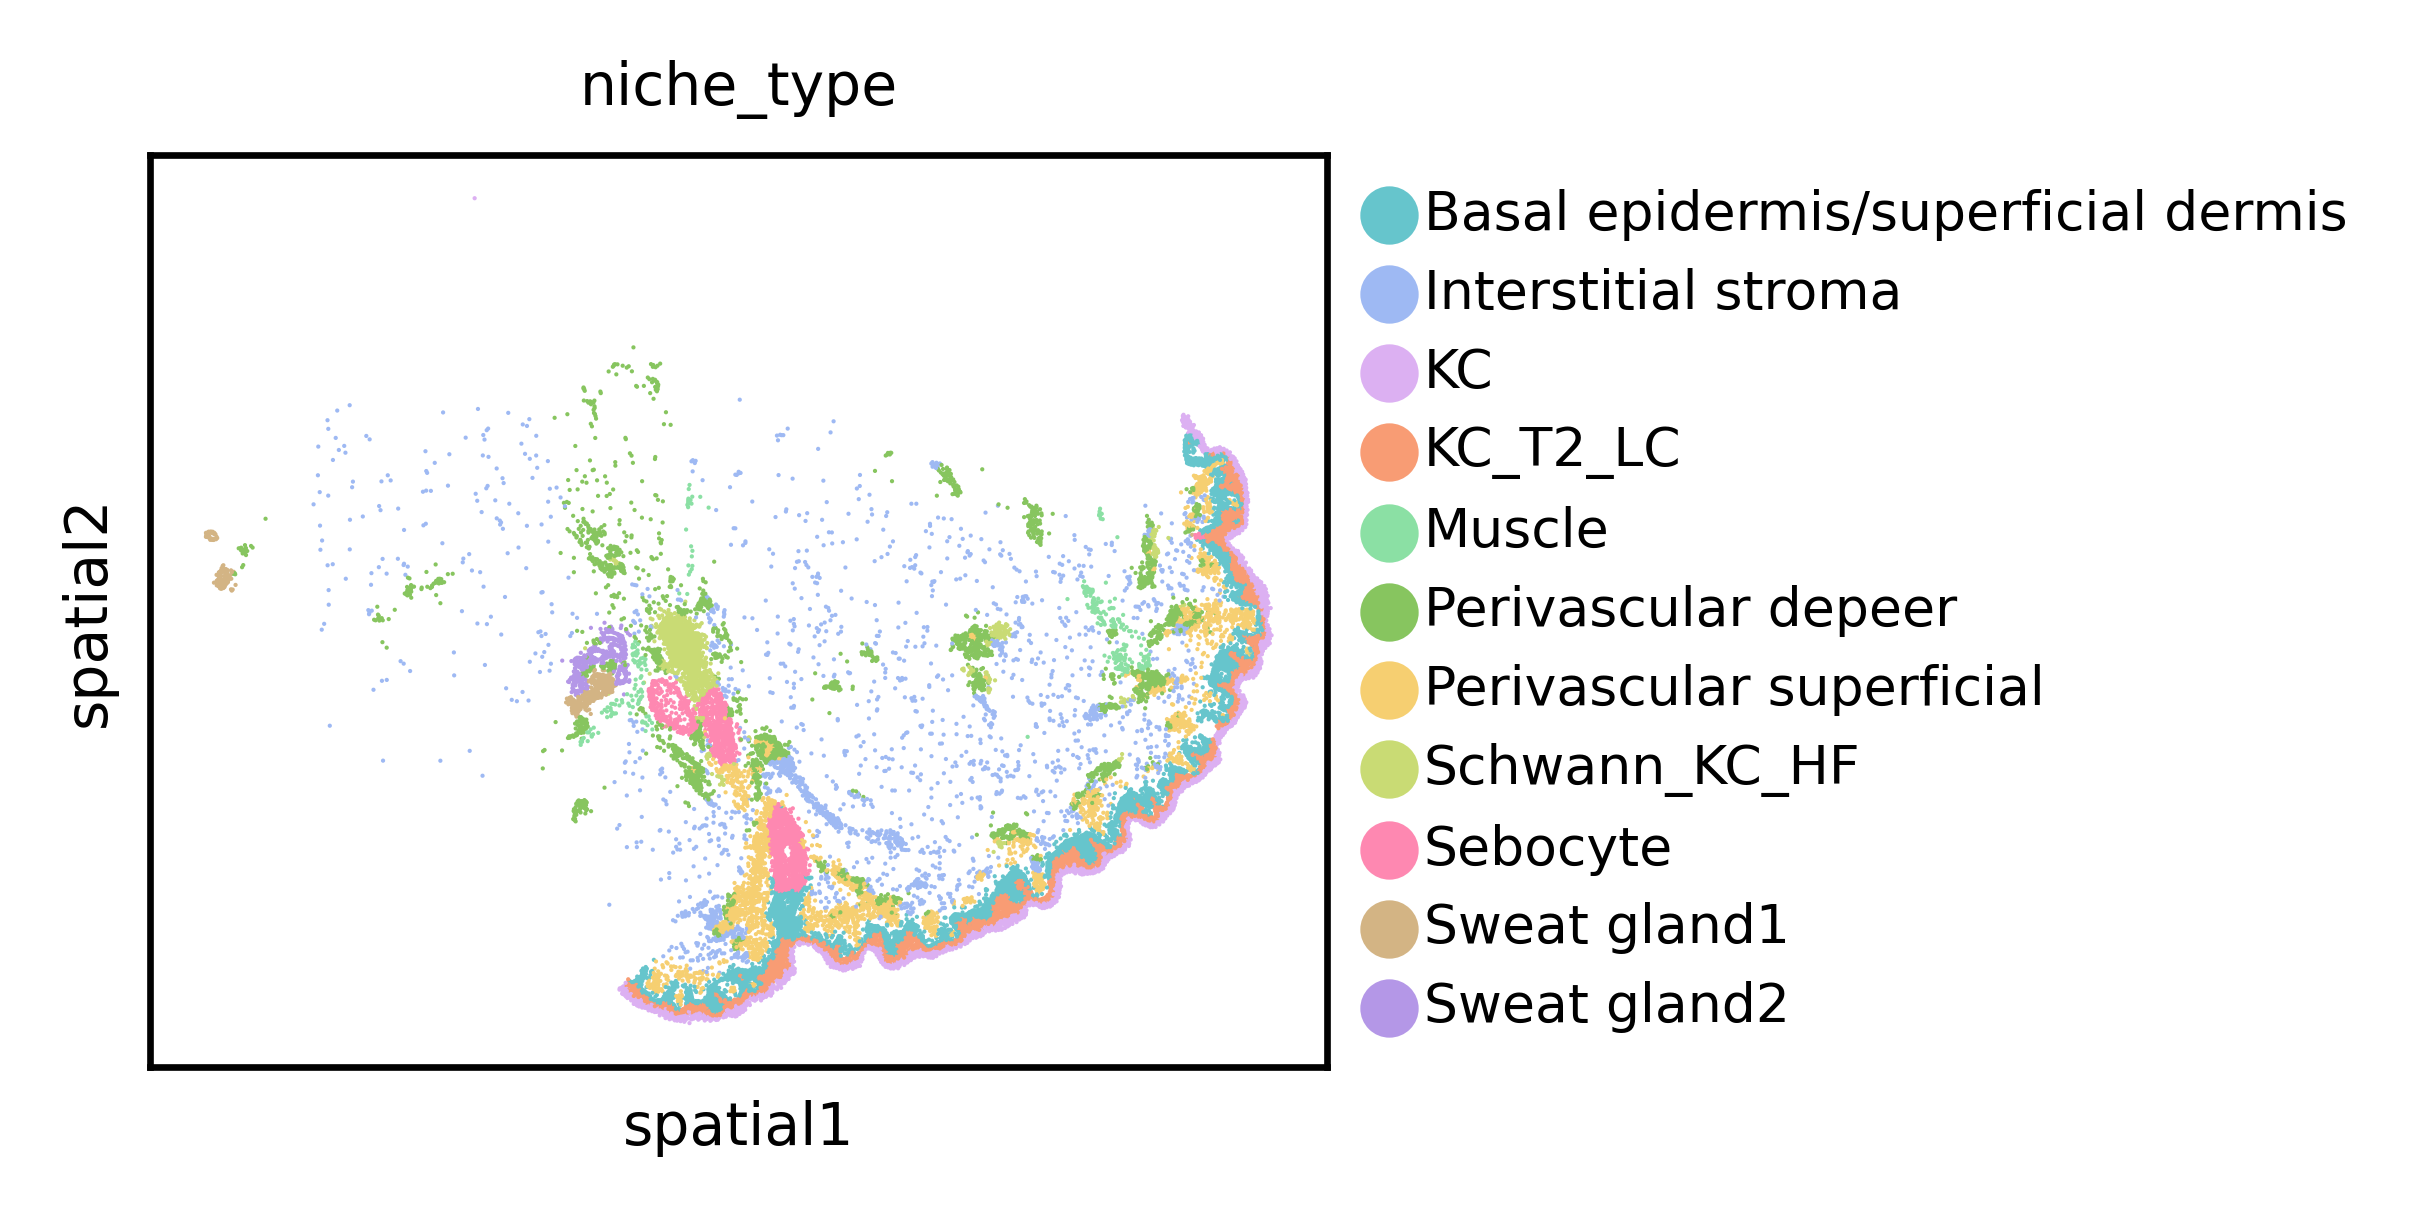

/tmp/ipykernel_2253437/3197656281.py:40: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


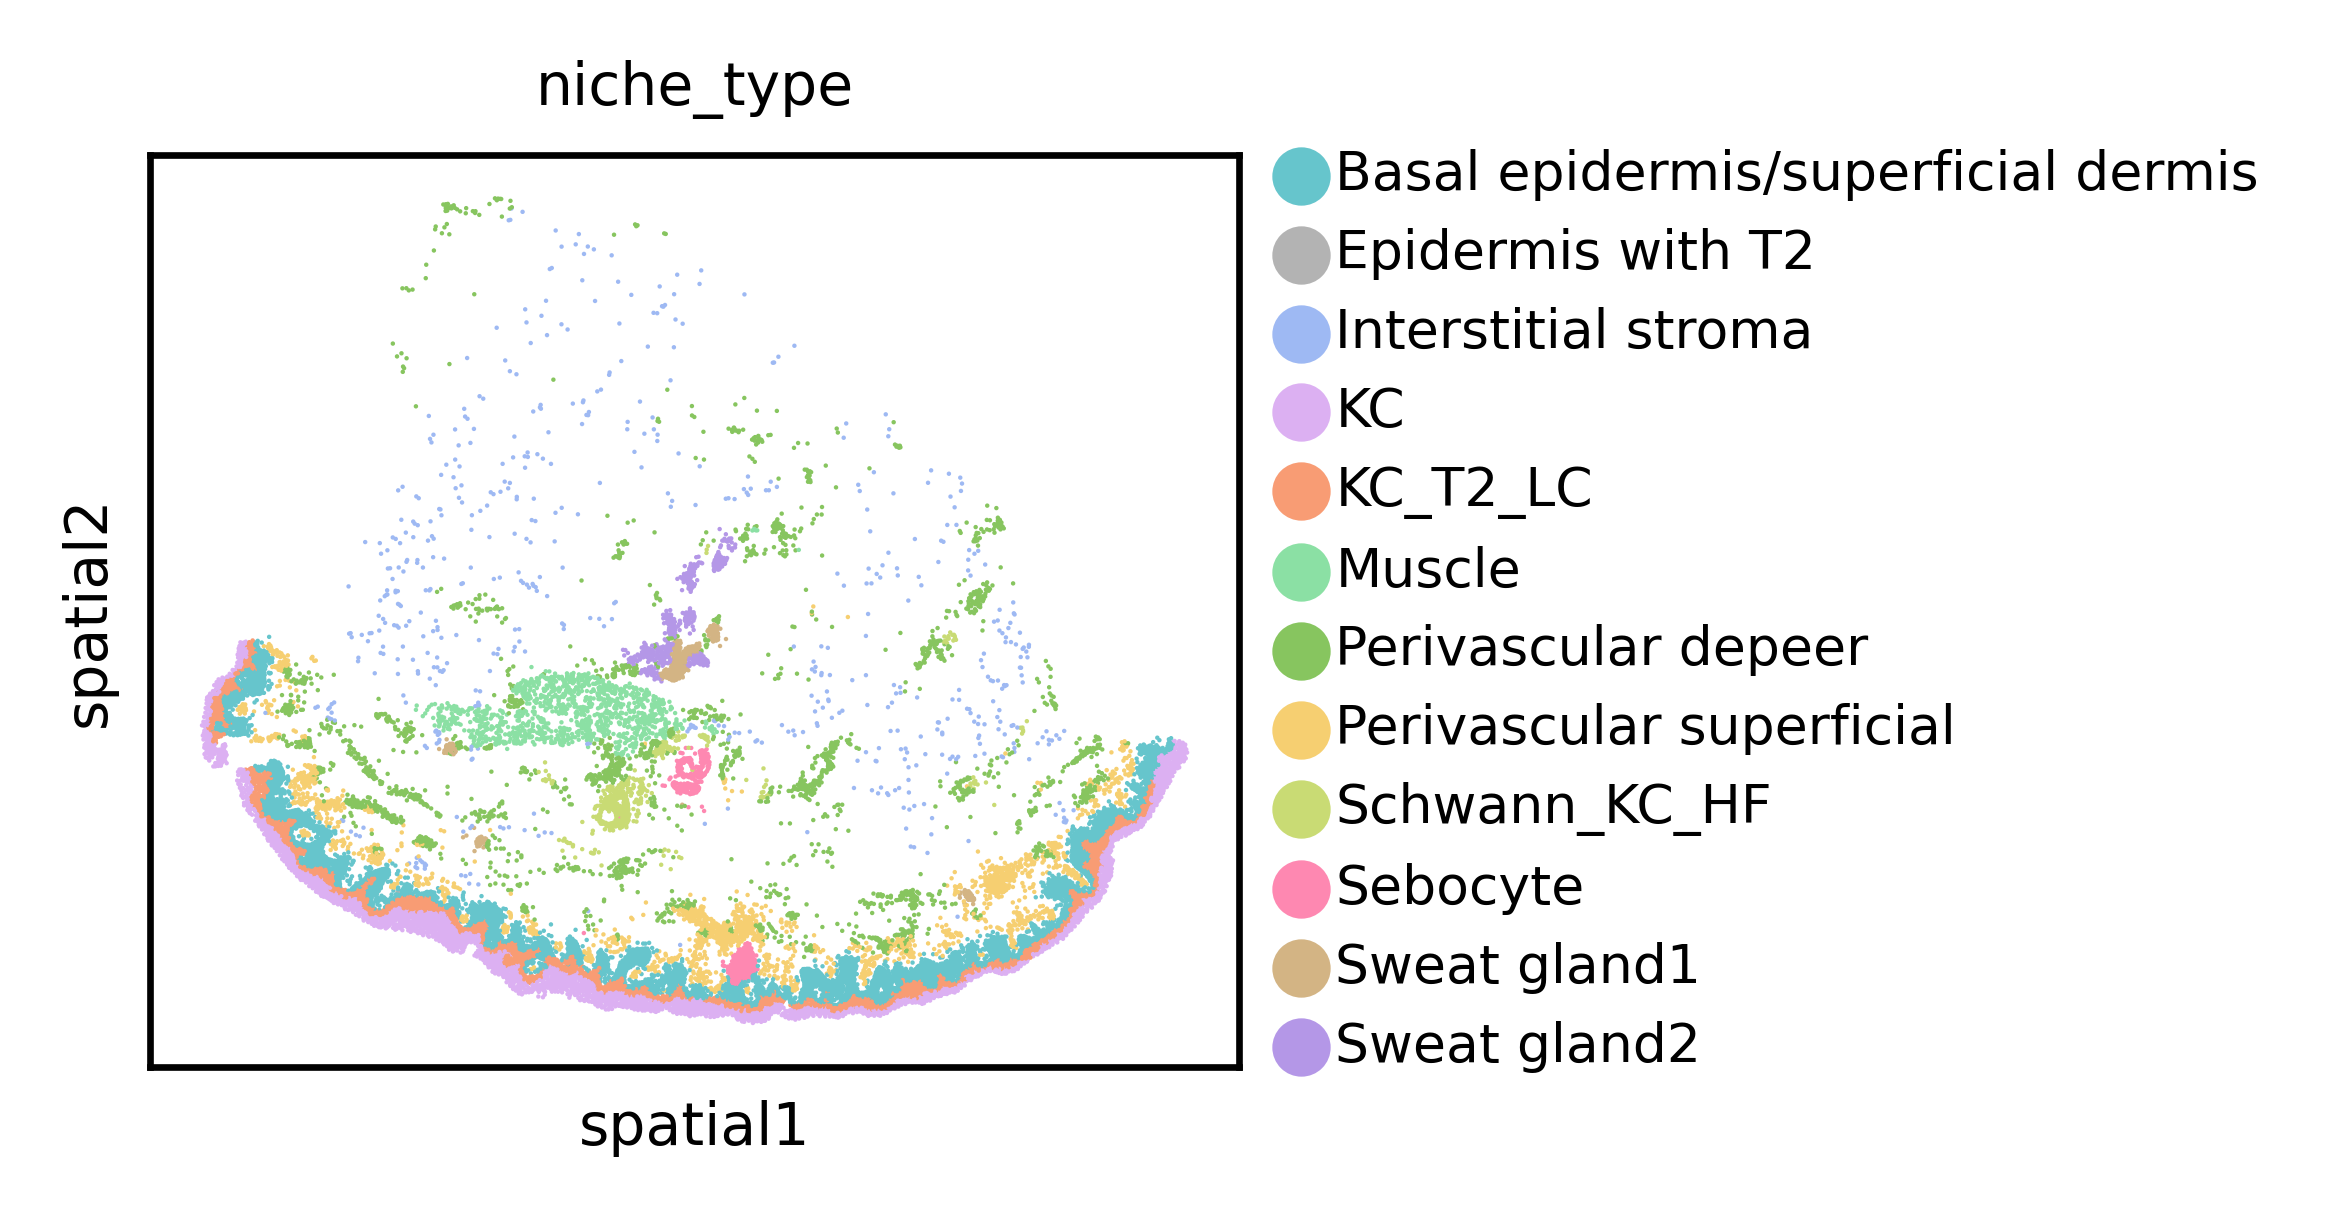

/tmp/ipykernel_2253437/3197656281.py:40: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


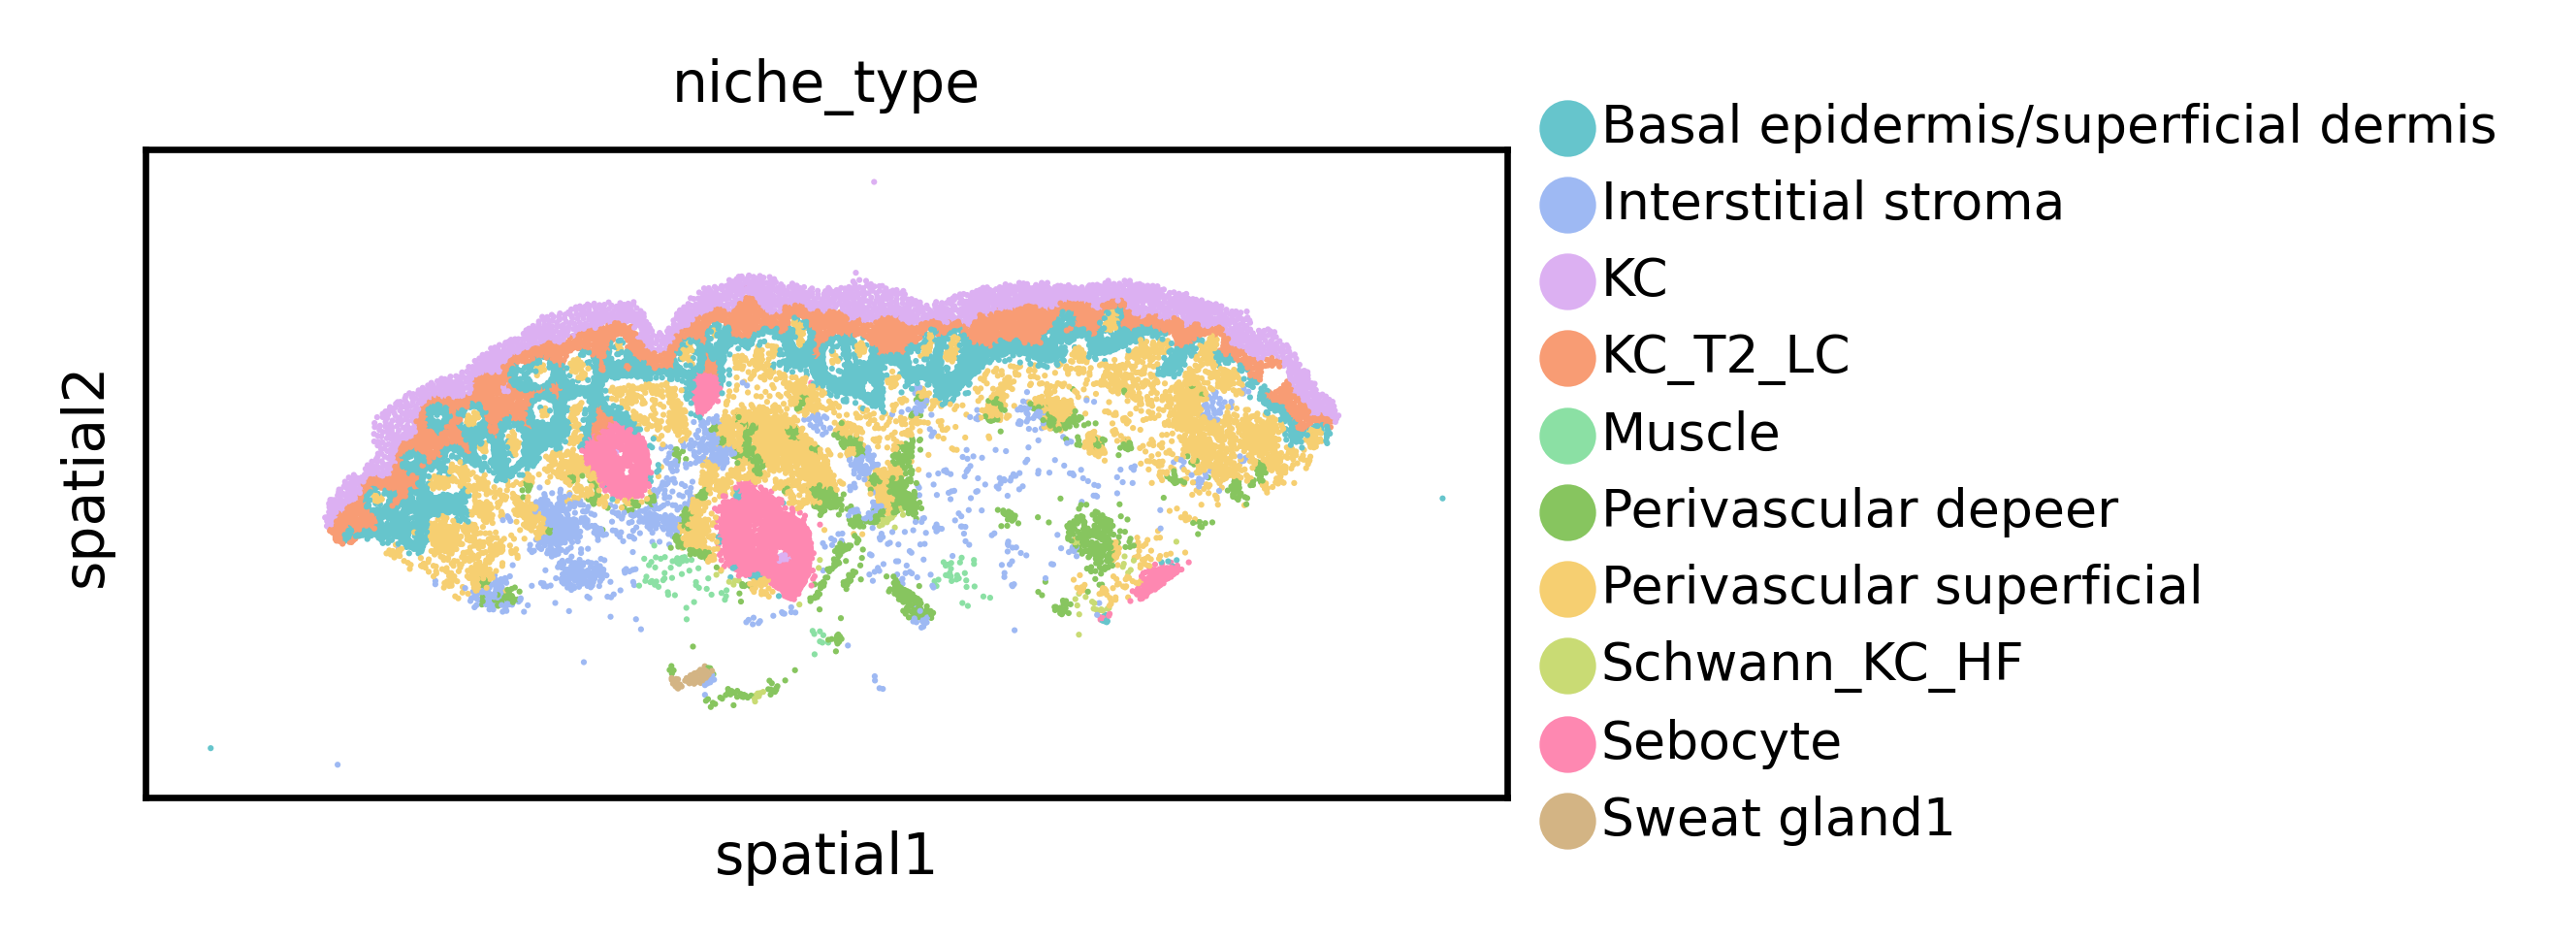

In [56]:
# Plot ground truth niches

# Label niches
label2niche = {
    '0': 'Basal epidermis/superficial dermis',
    '1': 'Perivascular superficial',
    '2': 'KC_T2_LC',
    '3': 'KC',
    '4': 'Perivascular depeer',
    '5': 'Interstitial stroma',
    '6': 'Sebocyte',
    '7': 'Schwann_KC_HF',
    '8': 'Muscle',
    '9': 'Sweat gland2',
    '10': 'Sweat gland1',
    '11': 'Epidermis with T2'
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

emb_key = "neighborhood"
adata_emb.obsm['X_umap'] = adata_emb.obsm[f'{emb_key}_umap']
sc.pl.umap(adata_emb,
           neighbors_key=emb_key,
           title=(emb_key + "_emb_" + niche_key),
           color=niche_key,
           palette=pred_palette,
           show=False)
plt.savefig(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/figures/{dataset_name}_{emb_key}_emb_umap_groundtruth_niches.svg',
            dpi=300,
            bbox_inches='tight')

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_groundtruth_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

/tmp/ipykernel_2253437/4293277701.py:31: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_utils.py:481: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


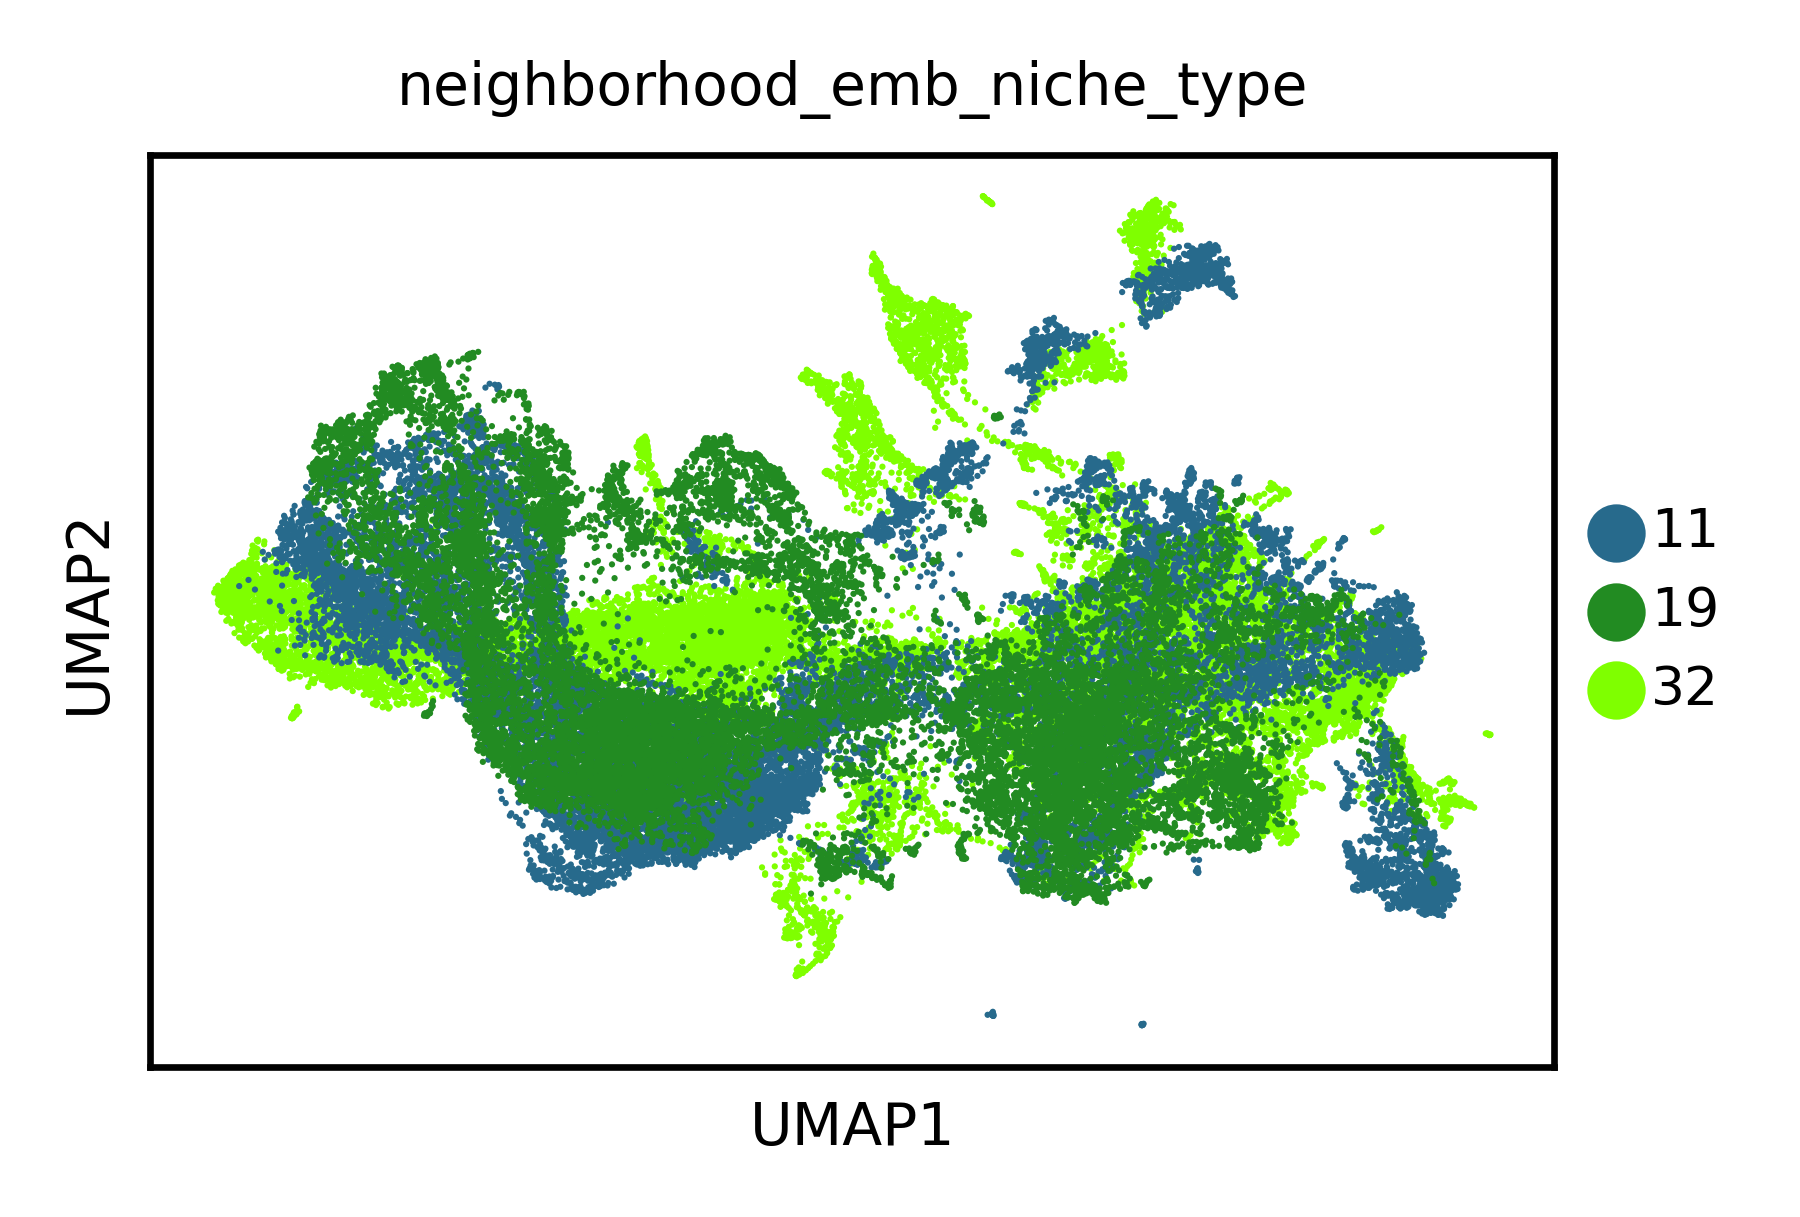

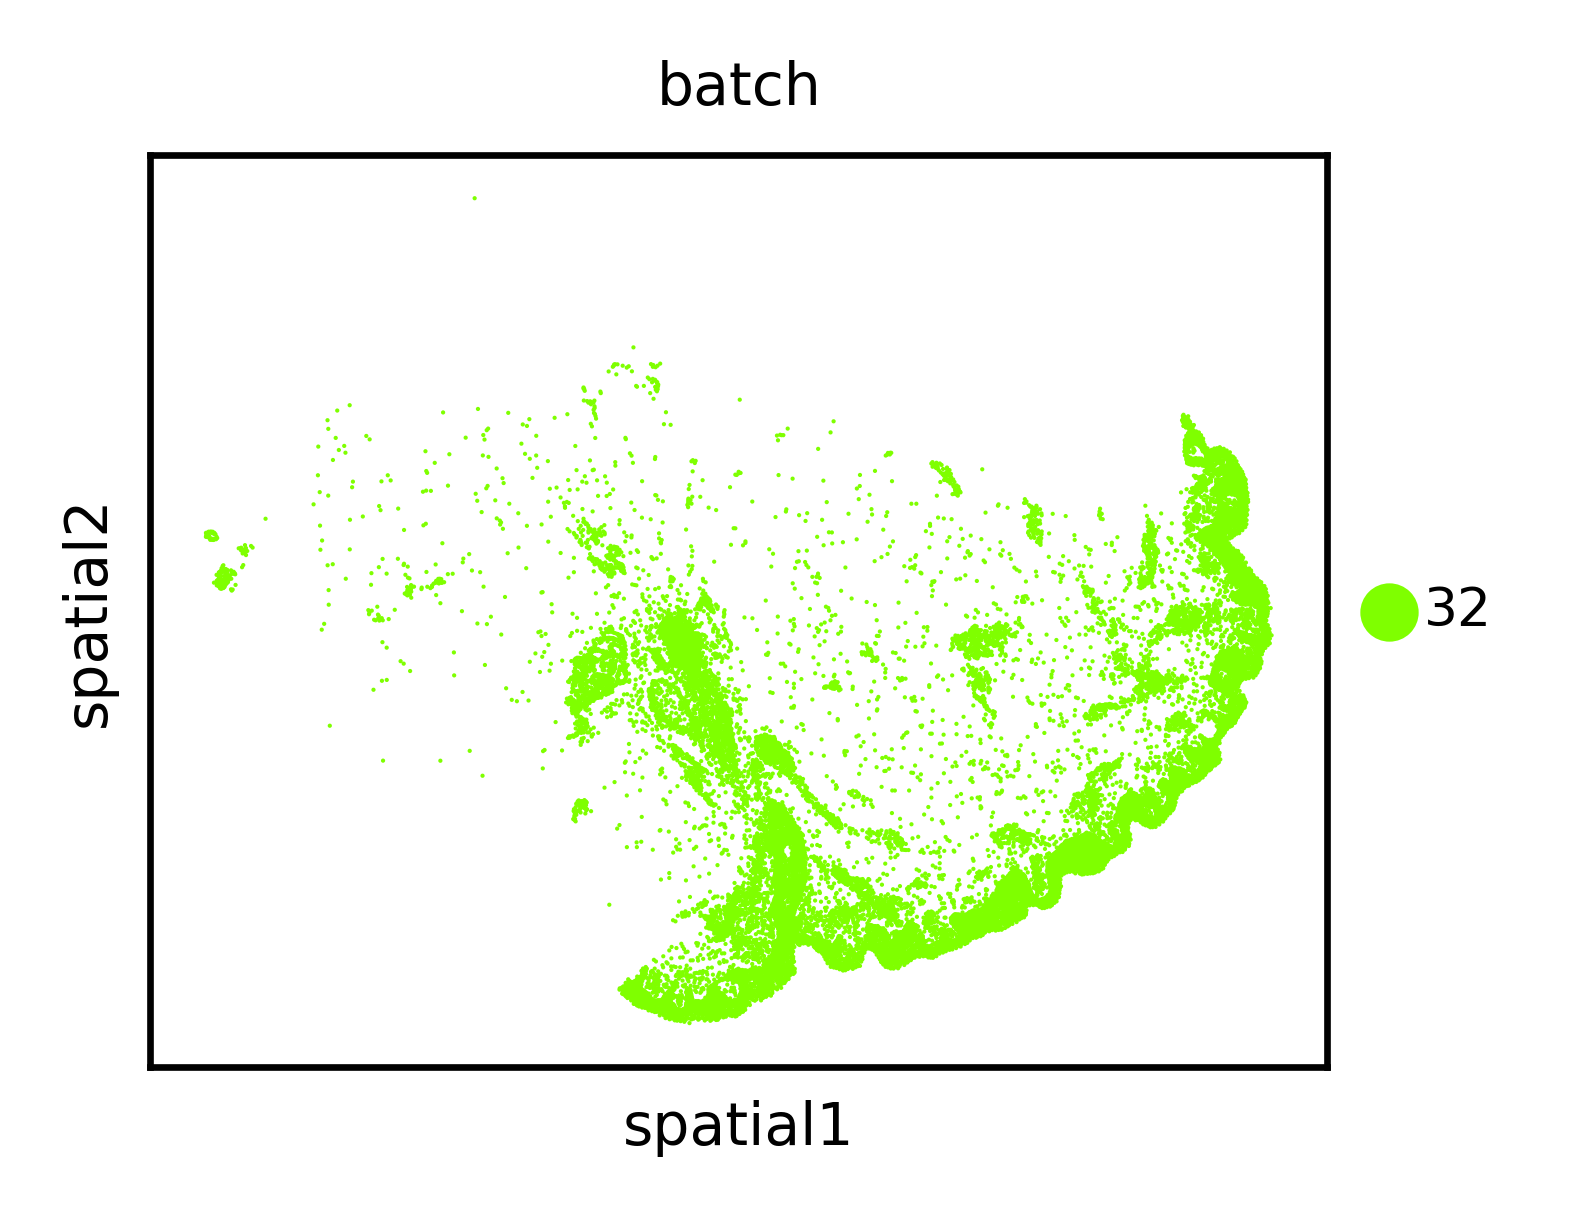

/tmp/ipykernel_2253437/4293277701.py:31: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_utils.py:481: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


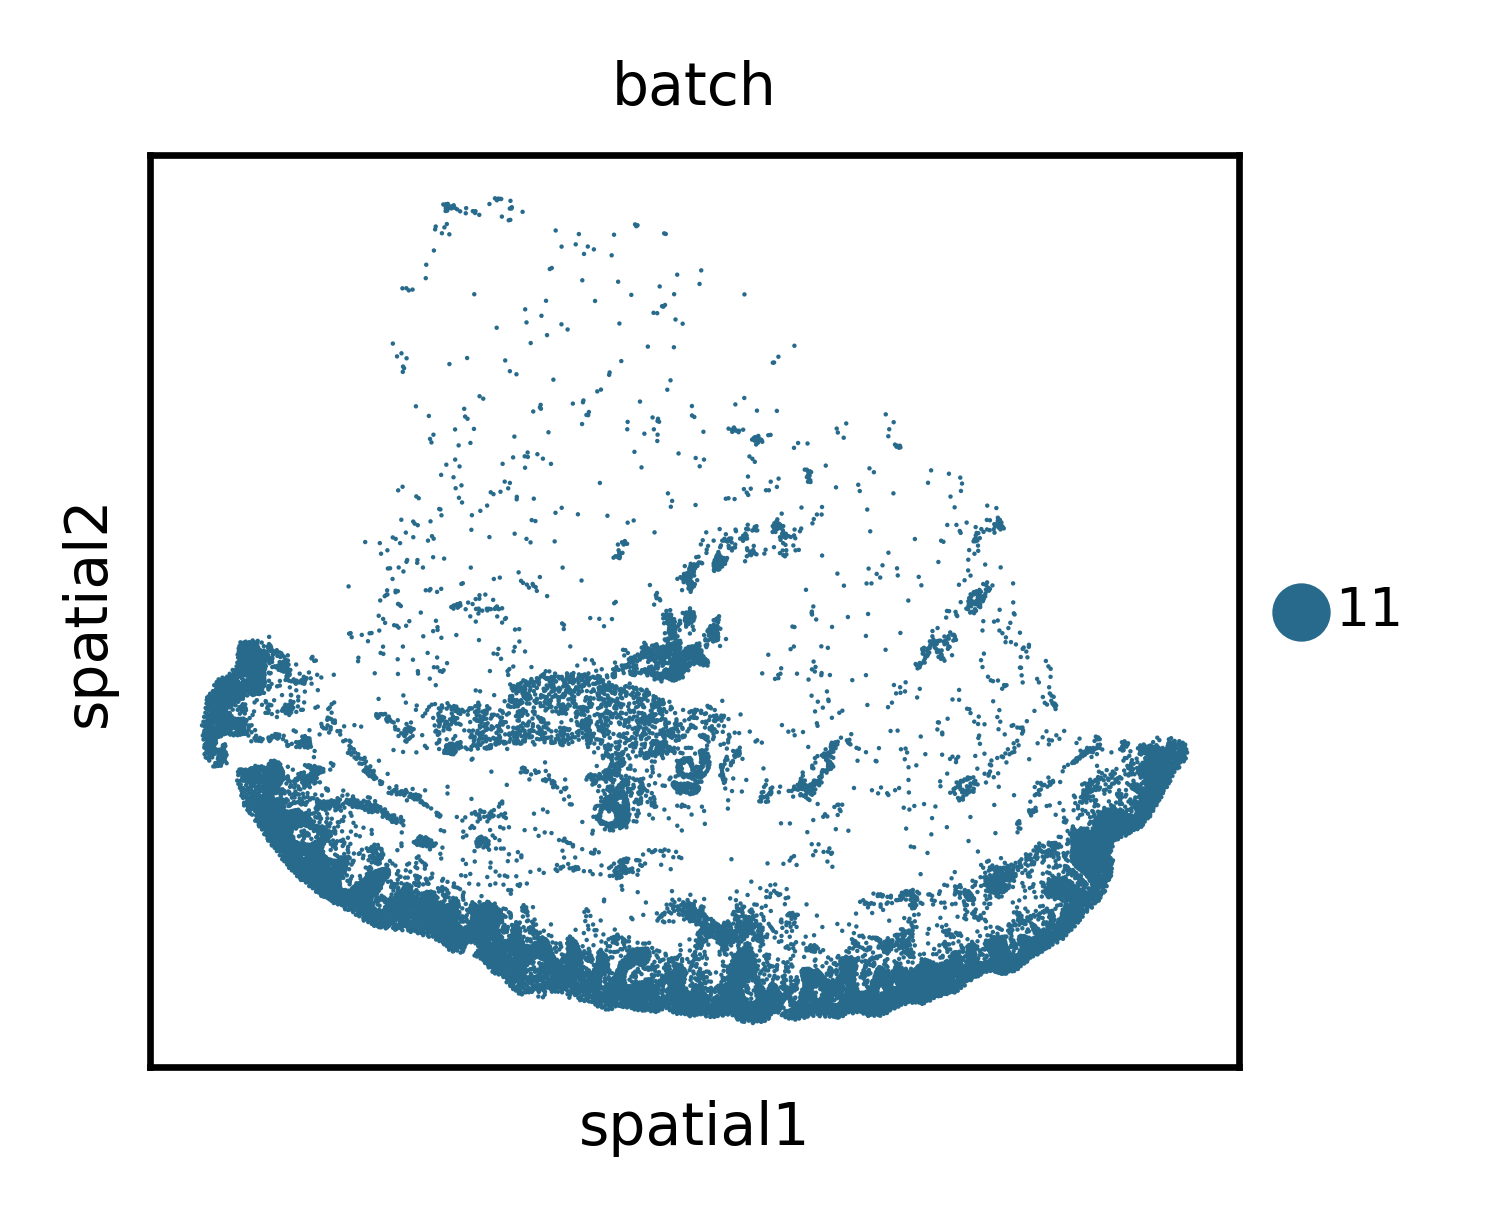

/tmp/ipykernel_2253437/4293277701.py:31: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_utils.py:481: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


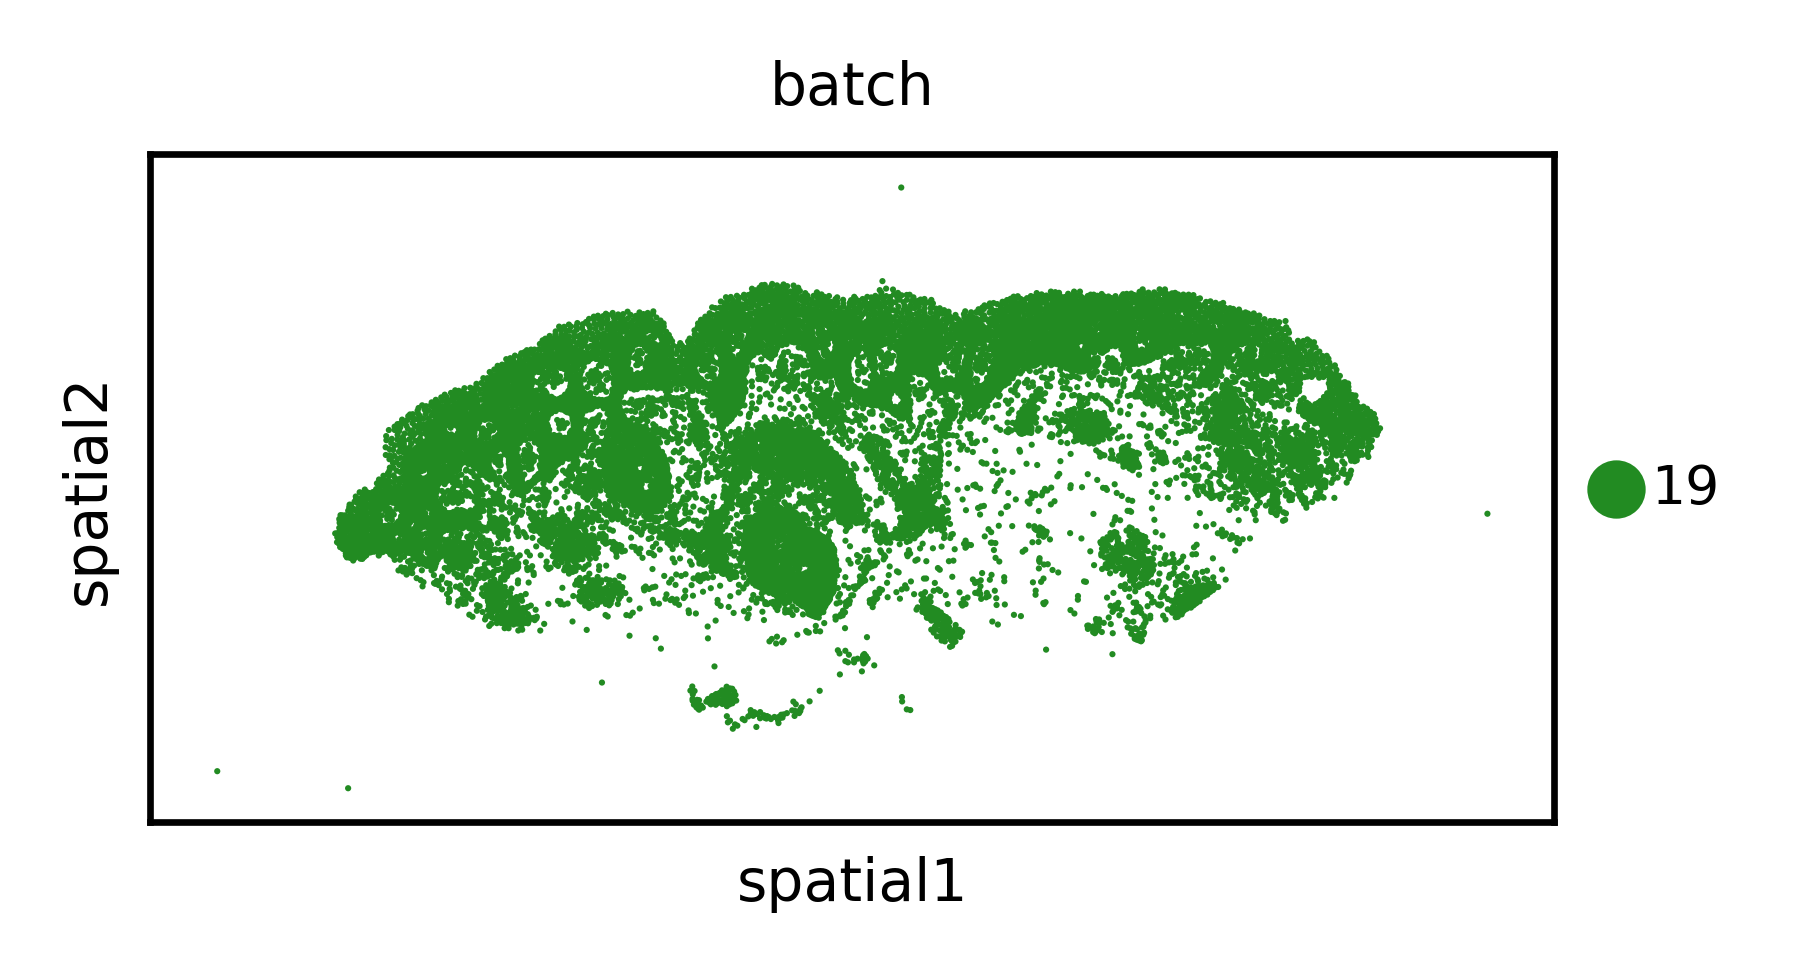

In [58]:
# Plot ground truth batches

# Label batches
label2batch = {
    '12': '11',
    '13': '19',
    '17': '32',
}

pred_palette = {
    label2batch.get(k, k): v
    for k, v in custom_palette.items()
}

emb_key = "neighborhood"
adata_emb.obsm['X_umap'] = adata_emb.obsm[f'{emb_key}_umap']
sc.pl.umap(adata_emb,
           neighbors_key=emb_key,
           title=(emb_key + "_emb_" + niche_key),
           color=batch_key,
           palette=pred_palette,
           show=False)
plt.savefig(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/figures/{dataset_name}_{emb_key}_emb_umap_batches.svg',
            dpi=300,
            bbox_inches='tight')

batch_ids = adata_emb.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_batches.svg'
    sc.pl.spatial(adata_batch,
                  color=batch_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

### 2.2 Cell Type Identification

#### 2.2.1 xhs1000-39b_1p (Xenium Human Skin - Eczema)

In [59]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
cell_type_key = 'new_annotation' # 'annotation_new7'
#batch_key = 'sample'
batch_key = 'batch'
spot_sizes = [20] * len(batches)
folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'

In [60]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial']

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [61]:
adata_emb = sc.read_h5ad(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

In [73]:
adata_emb.obs[cell_type_key] = adata.obs[cell_type_key].values

In [74]:
adata_emb.obs[cell_type_key].unique().tolist()

['KC4',
 'Mac',
 'T',
 'VE3',
 'cDC2',
 'Mast cell',
 'KC1',
 'KC_melanocyte',
 'F2: Universal',
 'Schwann',
 'Pericyte',
 'Muscle',
 'LE',
 'KC3',
 'KCinflamm',
 'Pre-adipocyte PPARG+ANGPTL8',
 'Sebocyte_GATA6hi_innersebocyte',
 'Sweat gland channel outer',
 'Sweat gland',
 'F5: RAMP1',
 'Plasma cell']

/tmp/ipykernel_2253437/2989170647.py:52: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


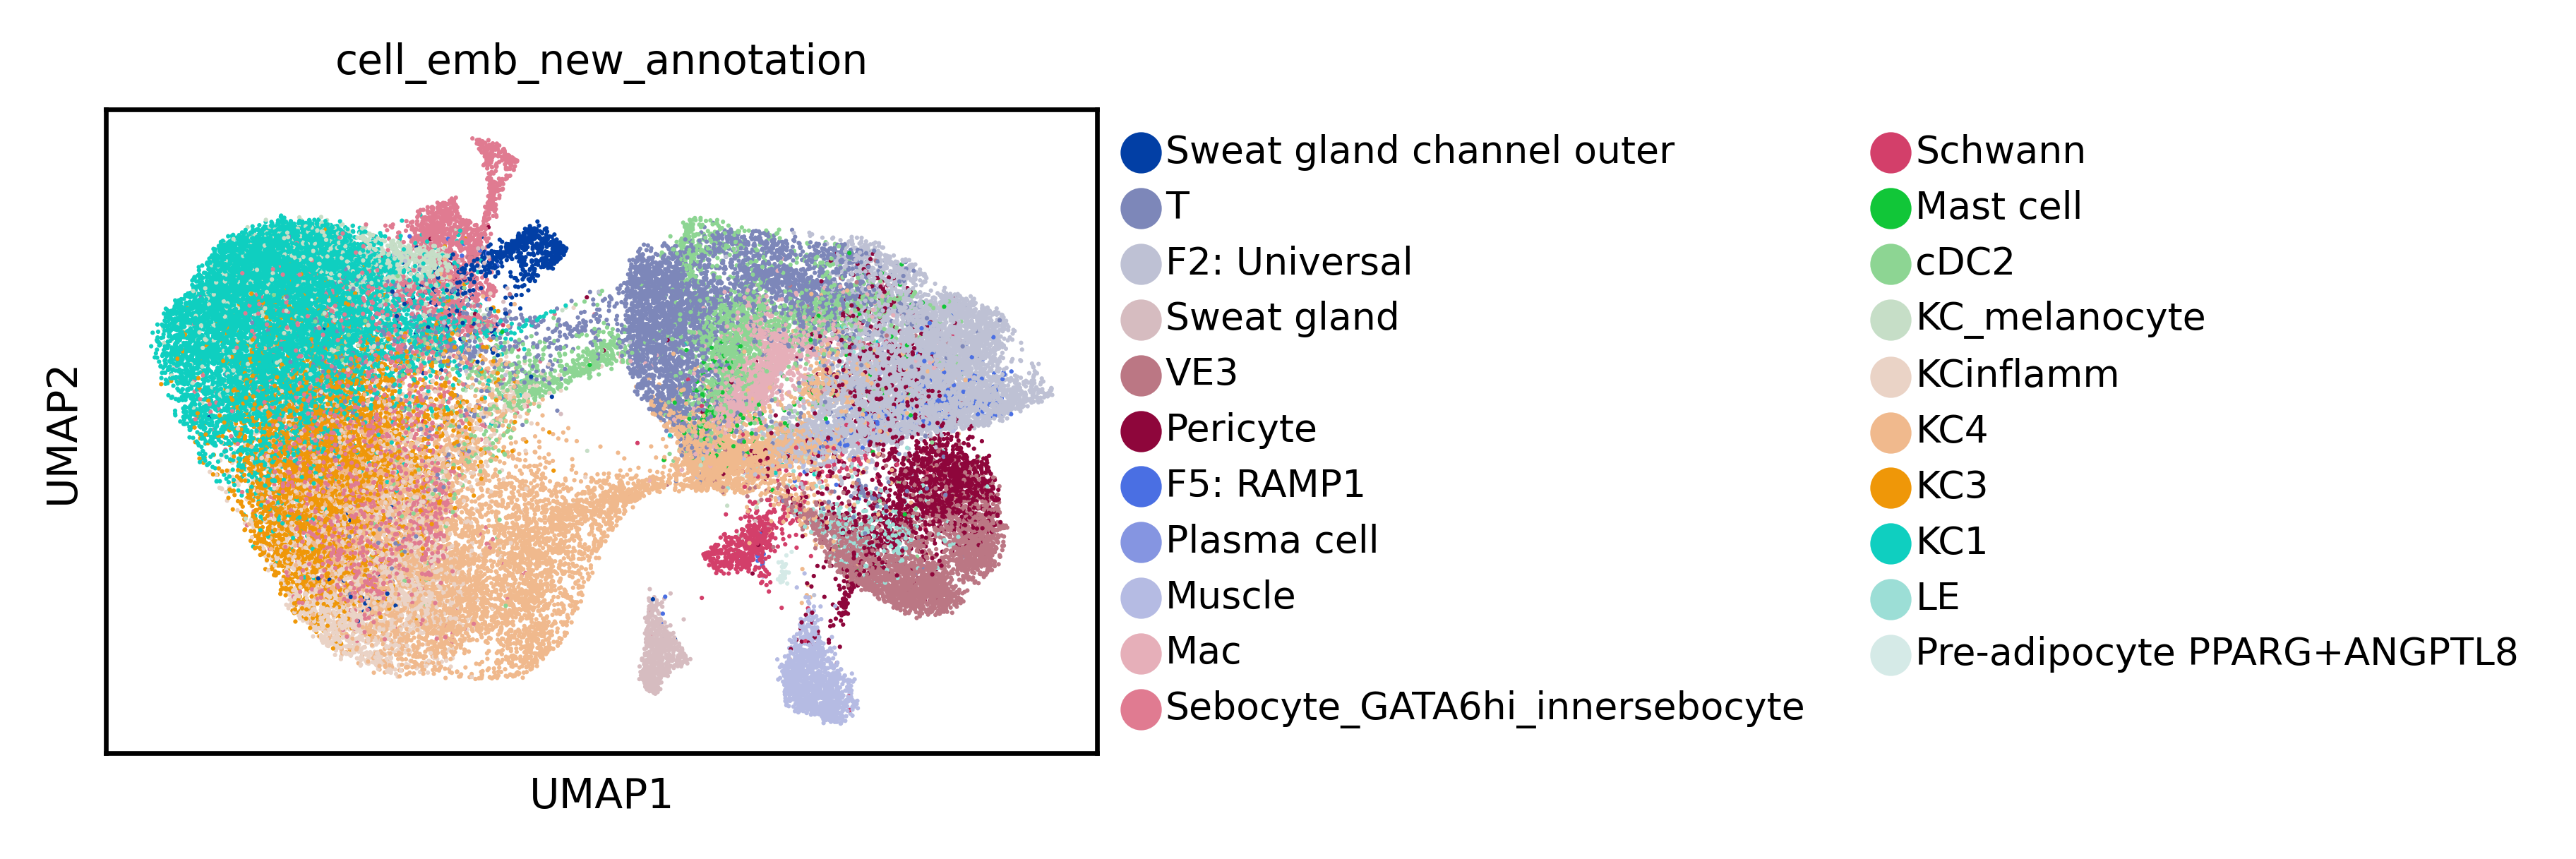

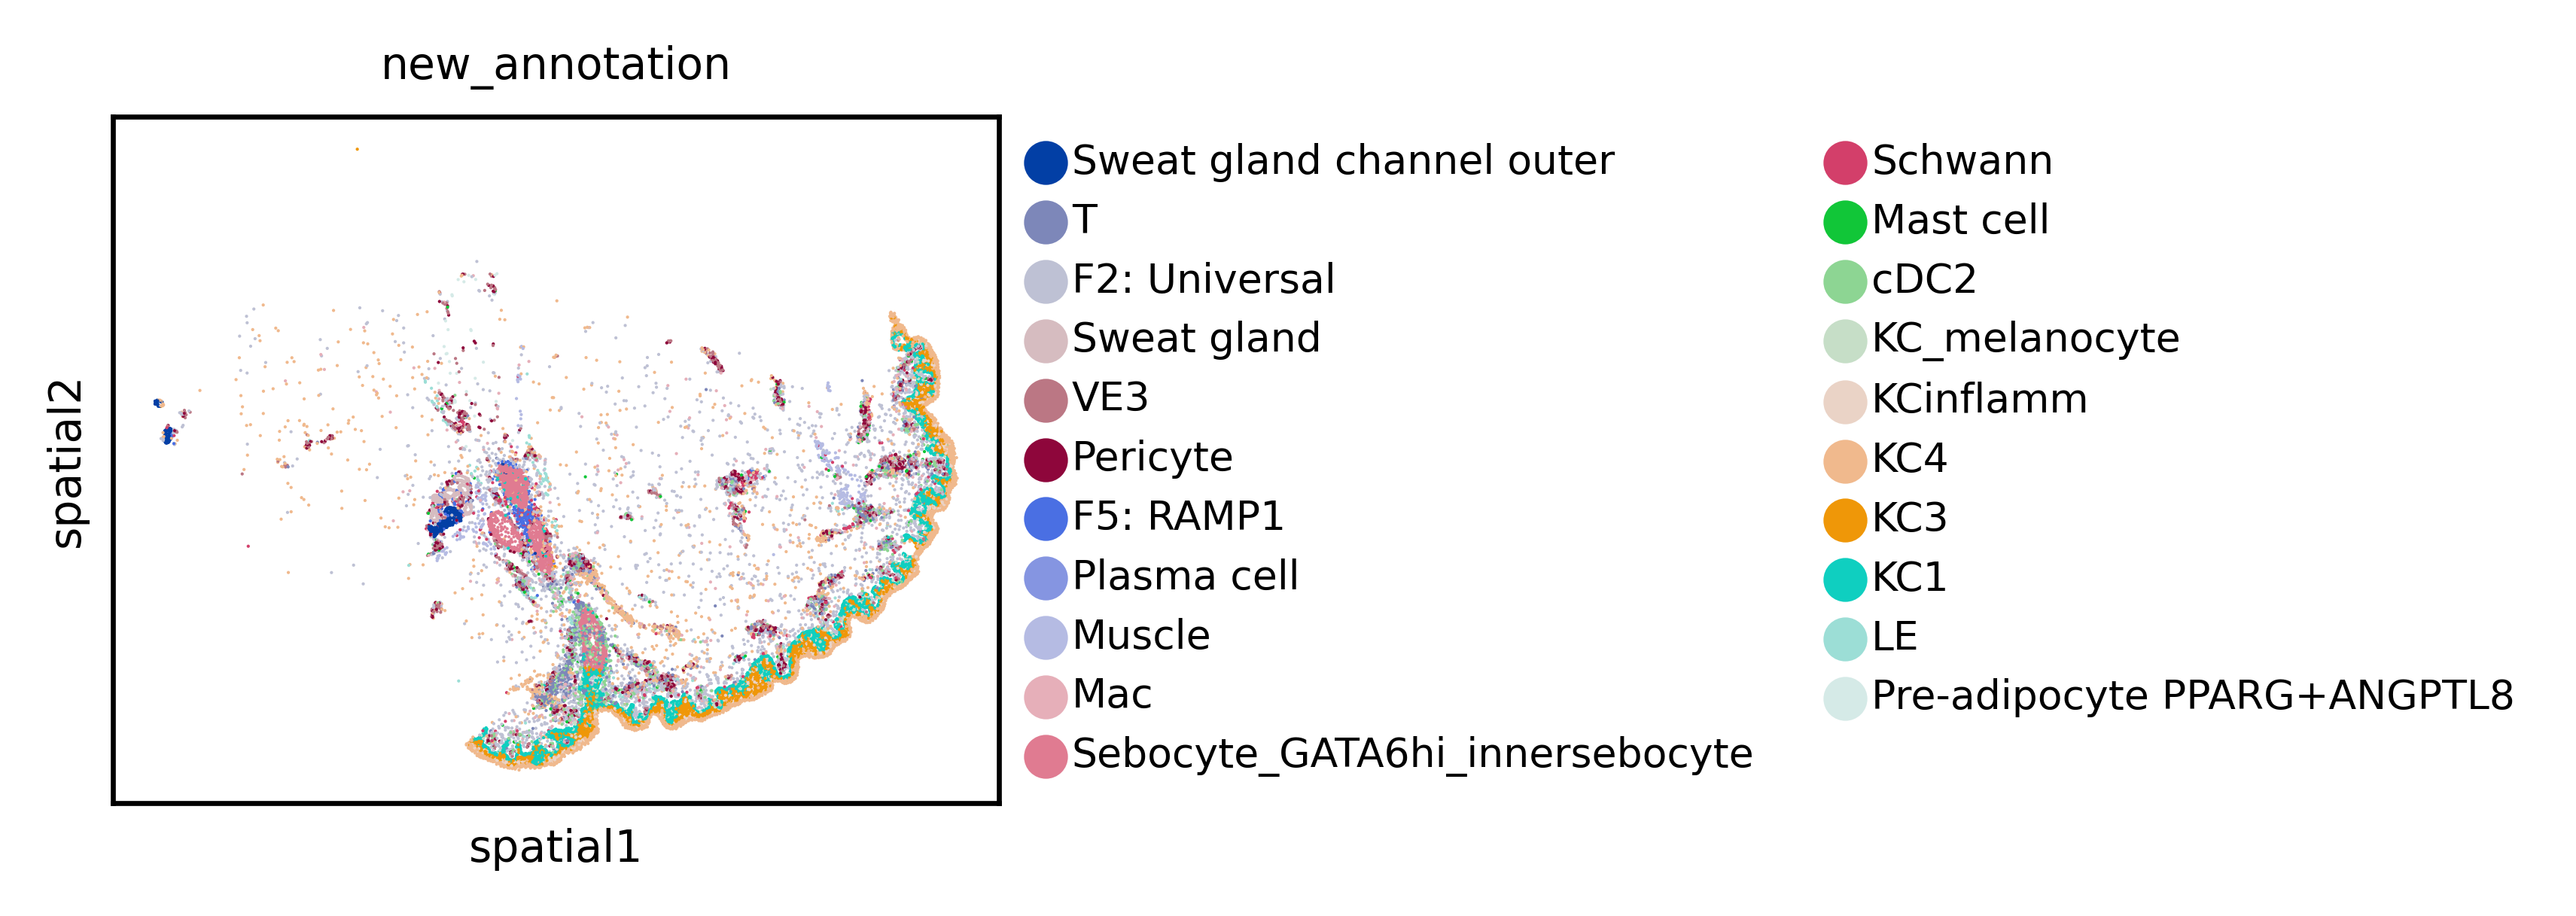

/tmp/ipykernel_2253437/2989170647.py:52: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


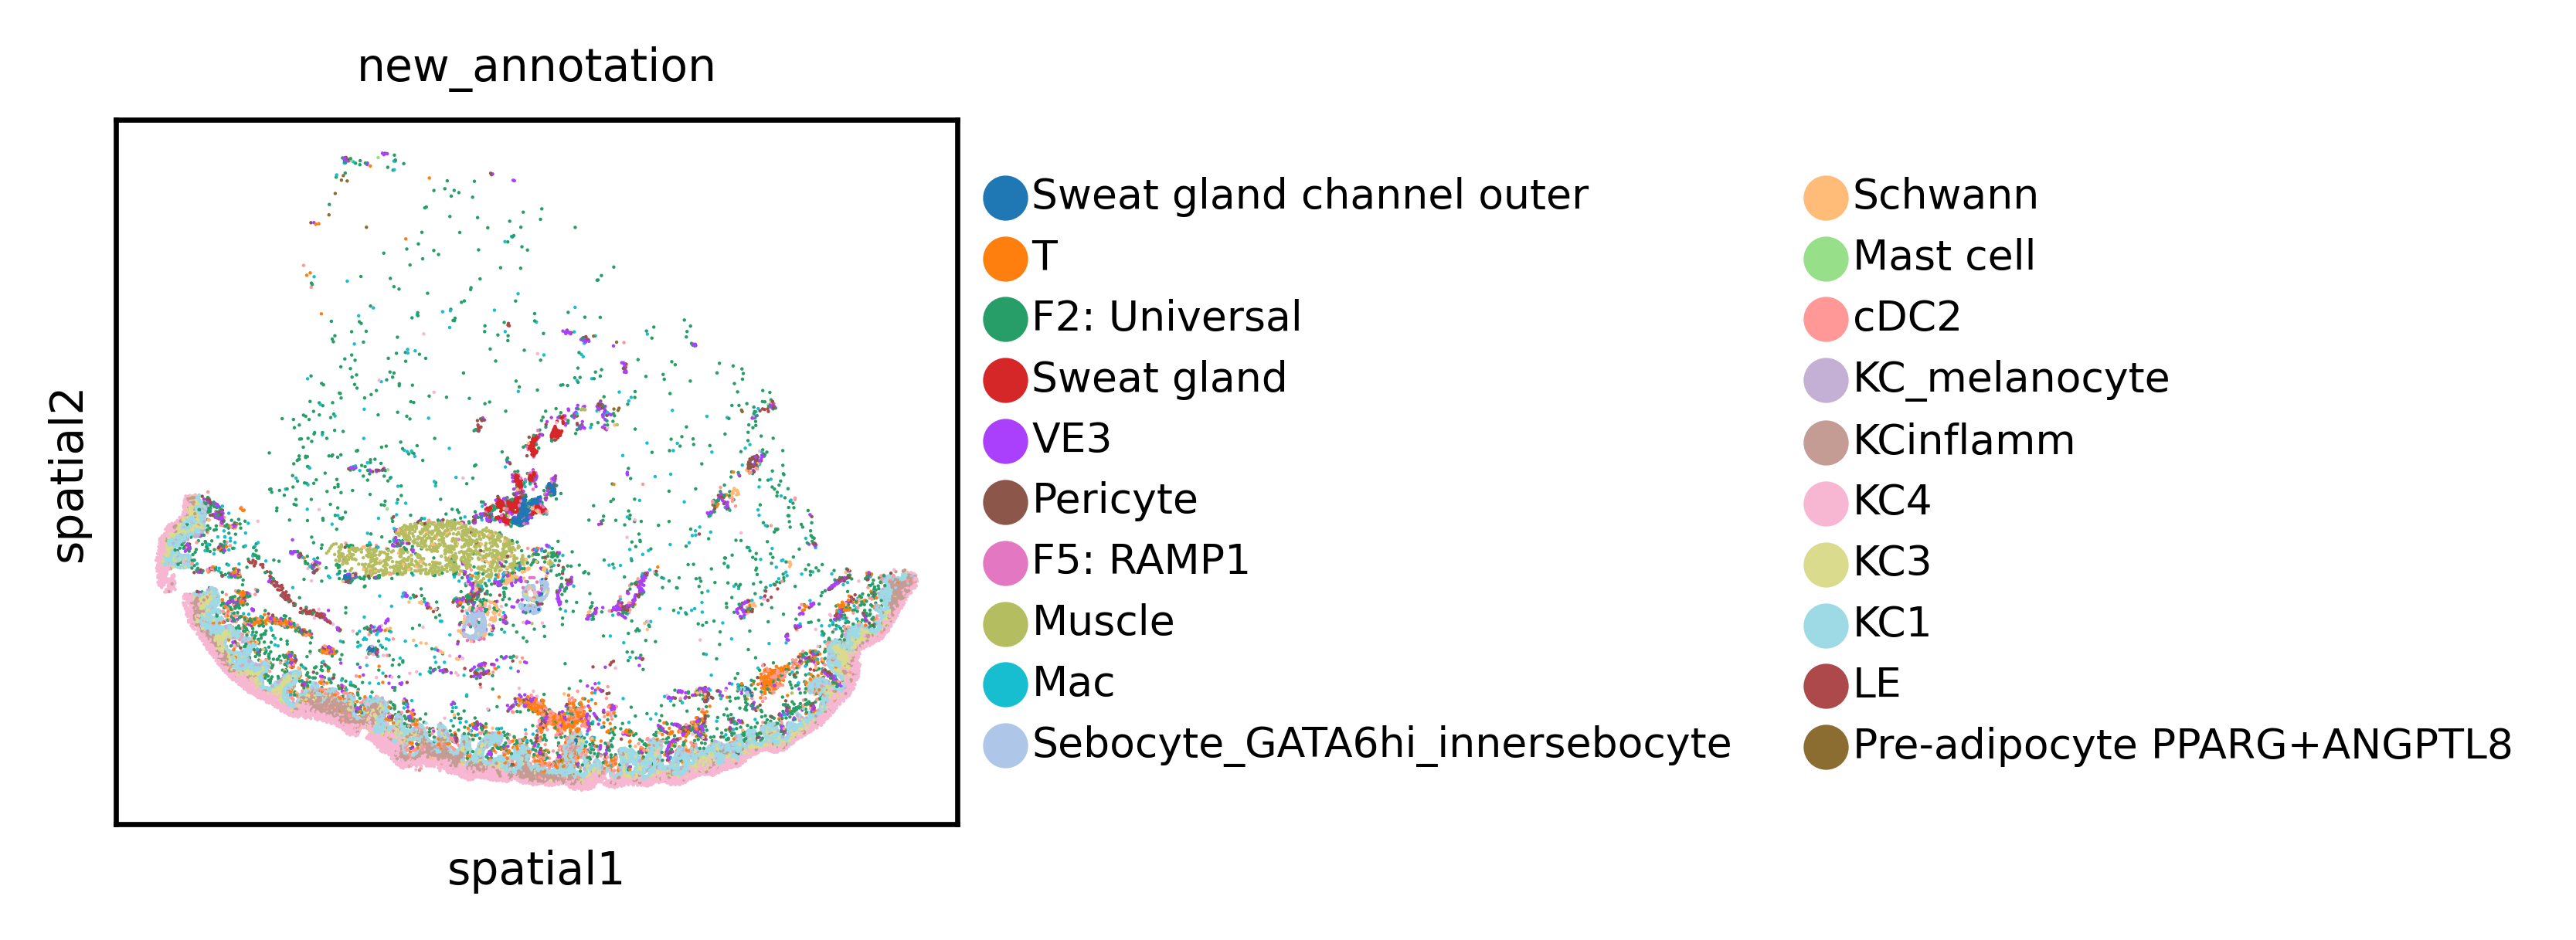

/tmp/ipykernel_2253437/2989170647.py:52: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


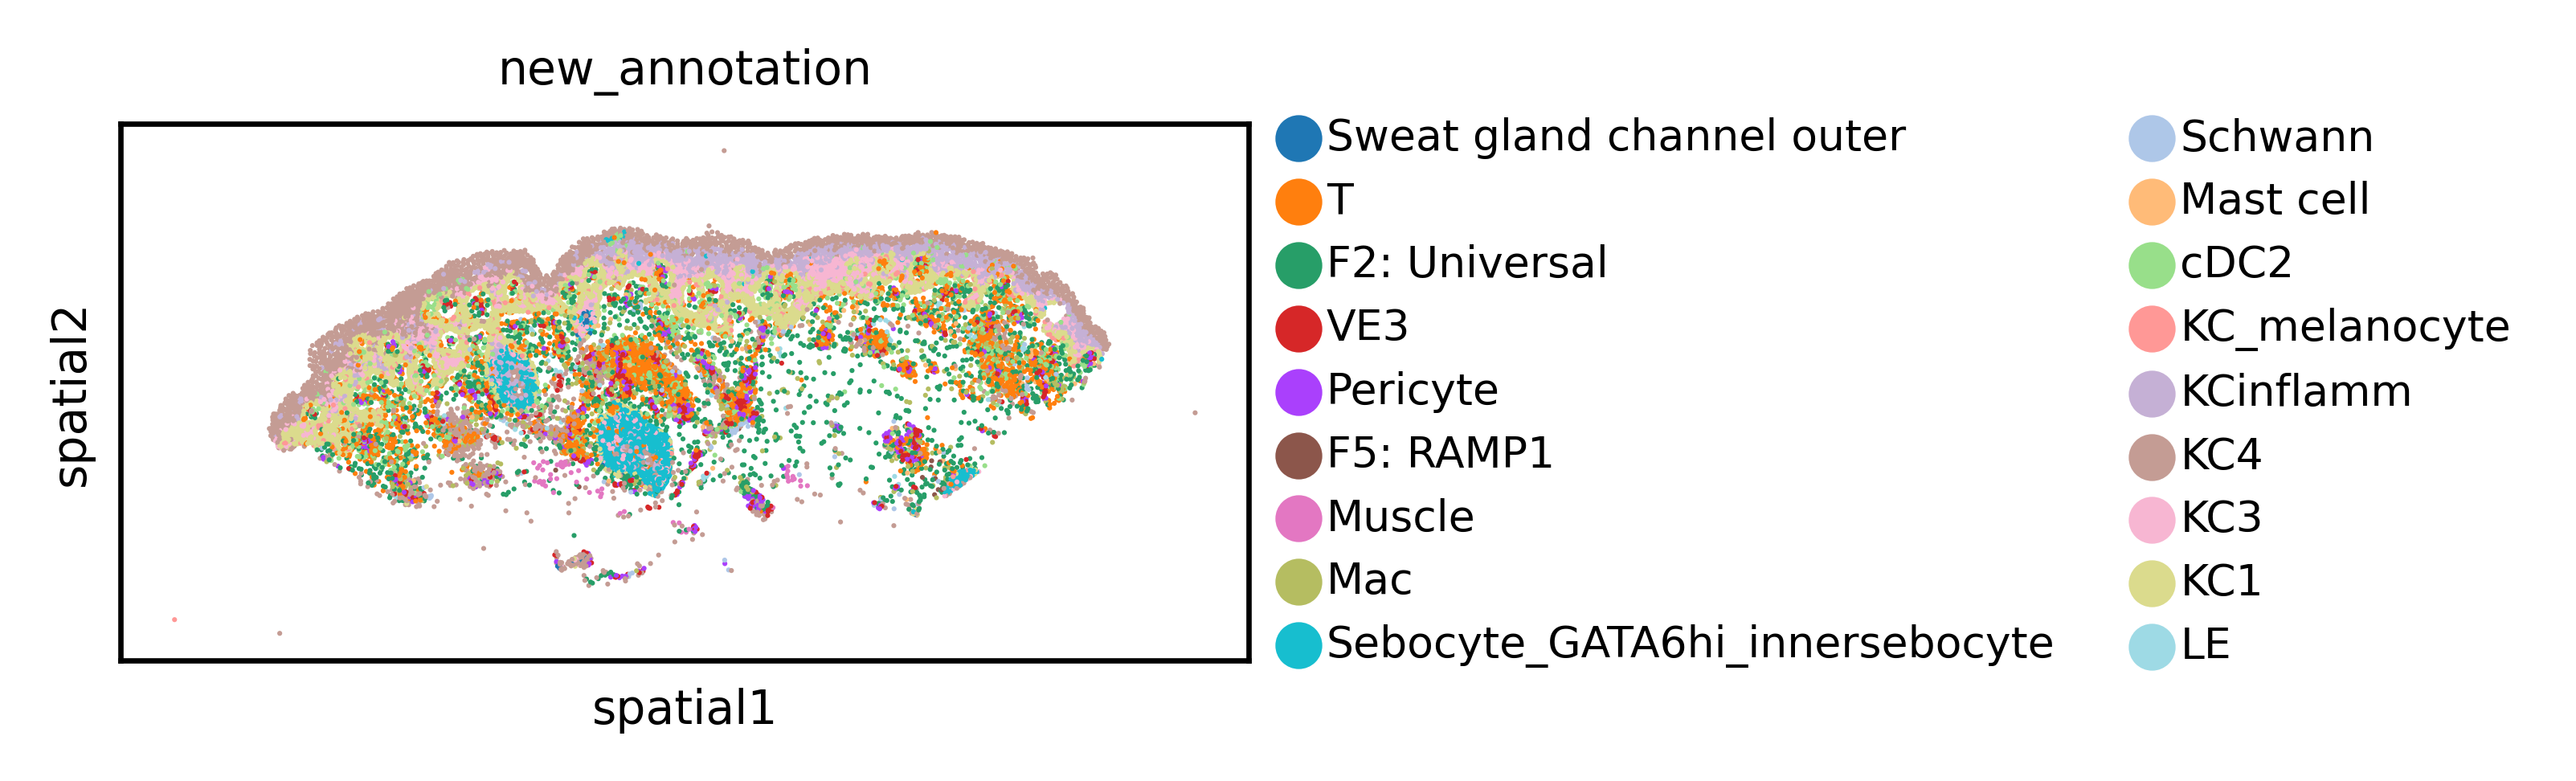

In [76]:
# Plot ground truth cell types

"""
# Label cell types
label2celltype = {
    '0': 'KC4',
    '1': 'Mac',
    '2': 'T',
    '3': 'VE3',
    '4': 'cDC2',
    '5': 'Mast cell',
    '6': 'KC1',
    '7': 'KC_melanocyte',
    '8': 'F2: Universal',
    '9': 'Schwann',
    '10': 'Pericyte',
    '11': 'Muscle',
    '12': 'LE',
    '13': 'KC3',
    '14': 'KCinflamm',
    '15': 'Pre-adipocyte PPARG+ANGPTL8',
    '16': 'Sebocyte_GATA6hi_innersebocyte',
    '17': 'Sweat gland channel outer',
    '18': 'Sweat gland,
    '19': 'F5: RAMP1',
    '20': 'Plasma cell',
}

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}
"""

emb_key = "cell"
adata_emb.obsm['X_umap'] = adata_emb.obsm[f'{emb_key}_umap']
sc.pl.umap(adata_emb,
           neighbors_key=emb_key,
           title=(emb_key + "_emb_" + cell_type_key),
           color=cell_type_key,
           #palette=pred_palette,
           show=False)
plt.savefig(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/figures/{dataset_name}_{emb_key}_emb_umap_cell_types.svg',
            dpi=300,
            bbox_inches='tight')


batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_groundtruth_cell_types.svg'
    sc.pl.spatial(adata_batch,
                  color=cell_type_key,
                  #palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Plot ground truth batches

# Label batches
label2batch = {
    '12': '11',
    '13': '19',
    '17': '32',
}

pred_palette = {
    label2batch.get(k, k): v
    for k, v in custom_palette.items()
}

emb_key = "cell"
adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']
sc.pl.umap(adata,
           neighbors_key=emb_key,
           title=(emb_key + "_emb_" + cell_type_key),
           color=batch_key,
           palette=pred_palette,
           show=False)
plt.savefig(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/figures/{dataset_name}_{emb_key}_emb_umap_batches.svg',
            dpi=300,
            bbox_inches='tight')

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_batches.svg'
    sc.pl.spatial(adata_batch,
                  color=batch_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

## 3. Niche Identification Metric Comparisons

In [ ]:
nichejepa_model_timestamp = '01112025_081731_614'

nichejepa_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
cellplm_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_cellplm_metric_scores.csv')
cellplm_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_cellplm_metric_scores.csv')
cellplm_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_cellplm_metric_scores.csv')
cellplm_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_cellplm_metric_scores.csv')
nicheformer_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nicheformer_metric_scores.csv')
nicheformer_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_nicheformer_metric_scores.csv')
nicheformer_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nicheformer_metric_scores.csv')
novae_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_novae_metric_scores.csv')
novae_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_novae_metric_scores.csv')
novae_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_novae_metric_scores.csv')
novae_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_novae_metric_scores.csv')
scgptspatial_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_scgpt-spatial_metric_scores.csv')

nichejepa_1000_df['dataset'] = 'Xenium\n Eczema'
nichejepa_49_df['dataset'] = 'Xenium\n Melanoma'
nichejepa_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
nichejepa_78_df['dataset'] = 'ISS Cartana\n Reproductive\n Tract'
cellplm_1000_df['dataset'] = 'Xenium\n Eczema'
cellplm_49_df['dataset'] = 'Xenium\n Melanoma'
cellplm_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
cellplm_78_df['dataset'] = 'ISS Cartana\n Reproductive\n Tract'
nicheformer_1000_df['dataset'] = 'Xenium\n Eczema'
nicheformer_49_df['dataset'] = 'Xenium\n Melanoma'
nicheformer_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
novae_1000_df['dataset'] = 'Xenium\n Eczema'
novae_49_df['dataset'] = 'Xenium\n Melanoma'
novae_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
novae_78_df['dataset'] = 'ISS Cartana\n Reproductive\n Tract'
scgptspatial_1000_df['dataset'] = 'Xenium\n Eczema'
scgptspatial_49_df['dataset'] = 'Xenium\n Melanoma'
scgptspatial_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
scgptspatial_78_df['dataset'] = 'ISS Cartana\n Reproductive\n Tract'

nichejepa_1000_df['method'] = 'TERRA'
nichejepa_49_df['method'] = 'TERRA'
nichejepa_59_df['method'] = 'TERRA'
nichejepa_78_df['method'] = 'TERRA'
cellplm_1000_df['method'] = 'CellPLM'
cellplm_49_df['method'] = 'CellPLM'
cellplm_59_df['method'] = 'CellPLM'
cellplm_78_df['method'] = 'CellPLM'
nicheformer_1000_df['method'] = 'Nicheformer'
nicheformer_49_df['method'] = 'Nicheformer'
nicheformer_59_df['method'] = 'Nicheformer'
scgptspatial_1000_df['method'] = 'scGPT-spatial'
scgptspatial_49_df['method'] = 'scGPT-spatial'
scgptspatial_59_df['method'] = 'scGPT-spatial'
scgptspatial_78_df['method'] = 'scGPT-spatial'
novae_1000_df['method'] = 'Novae'
novae_49_df['method'] = 'Novae'
novae_59_df['method'] = 'Novae'
novae_78_df['method'] = 'Novae'

df = pd.concat([nichejepa_1000_df,
                nichejepa_59_df,
                nichejepa_49_df,
                nichejepa_78_df,
                cellplm_1000_df,
                cellplm_59_df,
                cellplm_49_df,
                cellplm_78_df,
                nicheformer_1000_df,
                nicheformer_59_df,
                nicheformer_49_df,
                scgptspatial_1000_df,
                scgptspatial_59_df,
                scgptspatial_49_df,
                scgptspatial_78_df,
                novae_1000_df,
                novae_59_df,
                novae_49_df,
                novae_78_df],
               ignore_index=True)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

for metric in ["NMI", "ARI"]:
    fig, ax = plt.subplots(figsize=(4.9, 2.0))

    palette = "Set2"

    # ---- BARPLOT (default width to match stripplot) ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        palette=palette,
        dodge=True,
        ci=None,
        width=0.8,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- POINTS (CENTERED, NO JITTER) ----
    sns.stripplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        jitter=False,
        size=3.6,
        marker="o",
        edgecolor="black",
        linewidth=0.45,
        alpha=0.75,
        palette=palette,
        ax=ax
    )

    # ---- CLEAN LEGEND (SINGLE ROW, CENTERED) ----
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))
    if ax.legend_ is not None:
        ax.legend_.remove()

    methods = list(by_label.keys())
    colors = sns.color_palette(palette, len(methods))

    custom_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=m,
            markerfacecolor=colors[i],
            markeredgecolor="black",
            markersize=5.5
        )
        for i, m in enumerate(methods)
    ]

    ax.legend(
        handles=custom_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(custom_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )

    # ---- AXES ----
    ax.set_title(f"{metric} per Dataset", pad=3)
    #ax.set_xlabel("Dataset", labelpad=3)
    #ax.set_ylabel("")              # 🔑 remove y-axis label

    # Optional dataset separators
    for i in range(df["dataset"].nunique() - 1):
        ax.axvline(i + 0.5, color="black", linestyle="--", linewidth=0.9, zorder=0)

    # ---- WHITESPACE REMOVAL ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    n = df["dataset"].nunique()
    ax.set_xlim(-0.45, n - 0.55)
    ax.margins(x=0)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/figures/"
        f"benchmarking_comparison_{metric.lower()}_{nichejepa_model_timestamp}.svg",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

## 4. Cell Type Identification Metric Comparisons

In [ ]:
nichejepa_model_timestamp = '01112025_081731_614'

nichejepa_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nichejepa_metric_scores_cell_type_{nichejepa_model_timestamp}.csv')
#nichejepa_1007_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhk1007-CV1-41b_1p_nichejepa_metric_scores_cell_type_{nichejepa_model_timestamp}.csv')
nichejepa_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nichejepa_metric_scores_cell_type_{nichejepa_model_timestamp}.csv')
nichejepa_1016_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhp1016-18b_1p_nichejepa_metric_scores_cell_type_{nichejepa_model_timestamp}.csv')
nichejepa_75_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/shp75-4b_1p_nichejepa_metric_scores_cell_type_{nichejepa_model_timestamp}.csv')
cellplm_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_cellplm_metric_scores_cell_type.csv')
#cellplm_1007_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhk1007-CV1-41b_1p_cellplm_metric_scores_cell_type.csv')
cellplm_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_cellplm_metric_scores_cell_type.csv')
cellplm_1016_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhp1016-18b_1p_cellplm_metric_scores_cell_type.csv')
cellplm_75_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/shp75-4b_1p_cellplm_metric_scores_cell_type.csv')
nicheformer_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nicheformer_metric_scores_cell_type.csv')
#nicheformer_1007_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhk1007-CV1-41b_1p_nicheformer_metric_scores_cell_type.csv')
nicheformer_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nicheformer_metric_scores_cell_type.csv')
nicheformer_1016_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhp1016-18b_1p_nicheformer_metric_scores_cell_type.csv')
nicheformer_75_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/shp75-4b_1p_nicheformer_metric_scores_cell_type.csv')
scgptspatial_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_scgpt-spatial_metric_scores_cell_type.csv')
#scgptspatial_1007_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhk1007-CV1-41b_1p_scgpt-spatial_metric_scores_cell_type.csv')
scgptspatial_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_scgpt-spatial_metric_scores_cell_type.csv')
scgptspatial_1016_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhp1016-18b_1p_scgpt-spatial_metric_scores_cell_type.csv')
scgptspatial_75_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/shp75-4b_1p_scgpt-spatial_metric_scores_cell_type.csv')

nichejepa_1000_df['dataset'] = 'Xenium\n Eczema'
#nichejepa_1007_df['dataset'] = 'Xenium\n Renal Cell Carcinoma'
nichejepa_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
nichejepa_1016_df['dataset'] = 'Xenium\n Developing\n Pancreas\n'
nichejepa_75_df['dataset'] = 'STARmap\n Healthy\n Placenta\n'
cellplm_1000_df['dataset'] = 'Xenium\n Eczema'
#cellplm_1007_df['dataset'] = 'Xenium\n Renal Cell Carcinoma'
cellplm_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
cellplm_1016_df['dataset'] = 'Xenium\n Developing\n Pancreas\n'
cellplm_75_df['dataset'] = 'STARmap\n Healthy\n Placenta\n'
nicheformer_1000_df['dataset'] = 'Xenium\n Eczema'
#nicheformer_1007_df['dataset'] = 'Xenium\n Renal Cell Carcinoma'
nicheformer_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
nicheformer_1016_df['dataset'] = 'Xenium\n Developing\n Pancreas\n'
nicheformer_75_df['dataset'] = 'STARmap\n Healthy\n Placenta\n'
scgptspatial_1000_df['dataset'] = 'Xenium\n Eczema'
#scgptspatial_1007_df['dataset'] = 'Xenium\n Renal Cell Carcinoma'
scgptspatial_59_df['dataset'] = 'NanoString\n CosMx\n NSCLC'
scgptspatial_1016_df['dataset'] = 'Xenium\n Developing\n Pancreas\n'
scgptspatial_75_df['dataset'] = 'STARmap\n Healthy\n Placenta\n'

nichejepa_1000_df['method'] = 'TERRA'
#nichejepa_1007_df['method'] = 'TERRA'
nichejepa_59_df['method'] = 'TERRA'
nichejepa_1016_df['method'] = 'TERRA'
nichejepa_75_df['method'] = 'TERRA'
cellplm_1000_df['method'] = 'CellPLM'
#cellplm_1007_df['method'] = 'CellPLM'
cellplm_59_df['method'] = 'CellPLM'
cellplm_1016_df['method'] = 'CellPLM'
cellplm_75_df['method'] = 'CellPLM'
nicheformer_1000_df['method'] = 'Nicheformer'
#nicheformer_1007_df['method'] = 'Nicheformer'
nicheformer_59_df['method'] = 'Nicheformer'
nicheformer_1016_df['method'] = 'Nicheformer'
nicheformer_75_df['method'] = 'Nicheformer'
scgptspatial_1000_df['method'] = 'scGPT-spatial'
#scgptspatial_1007_df['method'] = 'scGPT-spatial'
scgptspatial_59_df['method'] = 'scGPT-spatial'
scgptspatial_1016_df['method'] = 'scGPT-spatial'
scgptspatial_75_df['method'] = 'scGPT-spatial'

df = pd.concat([nichejepa_1000_df,
                #nichejepa_1007_df,
                nichejepa_59_df,
                nichejepa_1016_df,
                nichejepa_75_df,
                cellplm_1000_df,
                #cellplm_1007_df,
                cellplm_59_df,
                cellplm_1016_df,
                cellplm_75_df,
                nicheformer_1000_df,
                #nicheformer_1007_df,
                nicheformer_59_df,
                nicheformer_1016_df,
                nicheformer_75_df,
                scgptspatial_1000_df,
                #scgptspatial_1007_df,
                scgptspatial_59_df,
                scgptspatial_1016_df,
                scgptspatial_75_df],
               ignore_index=True)

In [ ]:
df

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

for metric in ["NMI", "ARI"]:
    fig, ax = plt.subplots(figsize=(4.3, 2.0))

    palette = "Set2"

    # ---- BARPLOT (default width to match stripplot) ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        palette=palette,
        dodge=True,
        ci=None,
        width=0.8,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- POINTS (CENTERED, NO JITTER) ----
    sns.stripplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        jitter=False,
        size=3.6,
        marker="o",
        edgecolor="black",
        linewidth=0.45,
        alpha=0.75,
        palette=palette,
        ax=ax
    )

    # ---- CLEAN LEGEND (SINGLE ROW, CENTERED) ----
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))
    if ax.legend_ is not None:
        ax.legend_.remove()

    methods = list(by_label.keys())
    colors = sns.color_palette(palette, len(methods))

    custom_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=m,
            markerfacecolor=colors[i],
            markeredgecolor="black",
            markersize=5.5
        )
        for i, m in enumerate(methods)
    ]

    ax.legend(
        handles=custom_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(custom_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )

    # ---- AXES ----
    ax.set_title(f"{metric} per Dataset", pad=3)
    #ax.set_xlabel("Dataset", labelpad=3)
    #ax.set_ylabel("")              # 🔑 remove y-axis label

    # Optional dataset separators
    for i in range(df["dataset"].nunique() - 1):
        ax.axvline(i + 0.5, color="black", linestyle="--", linewidth=0.9, zorder=0)

    # ---- WHITESPACE REMOVAL ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    n = df["dataset"].nunique()
    ax.set_xlim(-0.45, n - 0.55)
    ax.margins(x=0)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/figures/"
        f"benchmarking_comparison_cell_type_{metric.lower()}_{nichejepa_model_timestamp}.svg",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

## 5. Niche Label Transfer Metric Comparisons

In [ ]:
def parse_classification_report(text):
    rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("precision"):
            continue

        parts = re.split(r"\s+", line)

        if parts[0] == "accuracy":
            rows.append({
                "label": "accuracy",
                "precision": None,
                "recall": None,
                "f1-score": float(parts[1]),
                "support": int(parts[2]),
            })
        elif parts[0] in {"macro", "weighted"}:
            rows.append({
                "label": f"{parts[0]} avg",
                "precision": float(parts[2]),
                "recall": float(parts[3]),
                "f1-score": float(parts[4]),
                "support": int(parts[5]),
            })
        else:
            rows.append({
                "label": parts[0],
                "precision": float(parts[1]),
                "recall": float(parts[2]),
                "f1-score": float(parts[3]),
                "support": int(parts[4]),
            })

    return rows

In [ ]:
n_seeds = 8

f1_scores_nichejepa = []
f1_scores_cellplm = []
f1_scores_nicheformer = []
f1_scores_novae = []
f1_scores_scgpt_spatial = []

for dataset_name in [
    'xhs1000-39b_1p',
    'xhs1000-39b_1p'
    #'chl59-8b_1p'
    ]:

    method = "NicheJEPA"
    nichejepa_model_timestamp = '01112025_081731_614'
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{nichejepa_model_timestamp}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nichejepa.append(macro_f1)

    method = "CellPLM"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_cellplm.append(macro_f1)

    method = "nicheformer"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nicheformer.append(macro_f1)

    method = "Novae"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_novae.append(macro_f1)

    method = "scGPT-spatial"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_scgpt_spatial.append(macro_f1)

In [ ]:
f1_lists = [
    f1_scores_nichejepa,
    f1_scores_cellplm,
    f1_scores_nicheformer,
    f1_scores_novae,
    f1_scores_scgpt_spatial
]

methods = [
    "NicheJEPA",
    "CellPLM",
    "Nicheformer",
    "Novae",
    "scGPT-spatial"
]

ds_lists = [[
    "Xenium\n Human Eczema\n (3 sections)"] * n_seeds + [
    "NanoString CosMx\n Human NSCLC\n (6 sections)"] * n_seeds] * 5

# Build dataframe
niche_transfer_df = pd.DataFrame({
    "F1": [f1 for sublist in f1_lists for f1 in sublist],
    "method": [m for m, sublist in zip(methods, f1_lists) for _ in sublist],
    "dataset": [ds for sublist in ds_lists for ds in sublist],
})

print(niche_transfer_df)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# Update plot settings
plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24,
    'legend.title_fontsize': 24
})

# Set the aesthetic style of the plots
sns.set(style="whitegrid")

for metric in ["F1"]:
    # Initialize the matplotlib figure with a specific size (wider plot)
    plt.figure(figsize=(5, 4))  # Increased width for a wider plot
    
    # Define a color palette (optional: customize as needed)
    palette = "Set2"
    
    # Create the boxplot
    ax = sns.boxplot(
        x='dataset',
        y=metric,
        hue='method',
        data=niche_transfer_df,
        palette=palette,
        dodge=True,
        showfliers=False  # Hide outliers for a cleaner look
    )
    
    # Overlay the scatter points with the same hue and palette
    sns.stripplot(
        x='dataset',
        y=metric,
        hue='method',
        data=niche_transfer_df,
        dodge=True,
        jitter=True,
        alpha=0.7,
        size=8,  # Increased dot size
        marker='o',
        edgecolor='black',  # Changed to black edges
        linewidth=1,        # Add linewidth for better edge visibility
        palette=palette,    # Ensure the palette matches the boxplot
        ax=ax
    )
    
    # Handle the legend to avoid duplicates
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))  # Remove duplicate labels
    
    # Remove the existing legend
    ax.legend_.remove()
    
    # Create custom legend handles with desired properties
    unique_methods = list(by_label.keys())
    palette_colors = sns.color_palette(palette, n_colors=len(unique_methods))
    
    custom_handles = [
        Line2D([0], [0], marker='o', color='w', label=method,
               markerfacecolor=palette_colors[i],
               markeredgecolor='black', markersize=10)
        for i, method in enumerate(unique_methods)
    ]
    
    # Add the custom legend
    ax.legend(handles=custom_handles, title='Method')
    
    # Add titles and labels with appropriate font sizes
    plt.title(f'{metric} Distribution per Dataset and Method')
    plt.xlabel('Dataset')
    plt.ylabel(metric)
    
    # Add black striped lines between x-axis values (datasets)
    num_datasets = len(niche_transfer_df['dataset'].unique())
    for i in range(num_datasets - 1):
        ax.axvline(x=i + 0.5, color='black', linestyle='--', linewidth=2)  # Dashed black lines
    
    # Adjust layout for better fit and prevent clipping of labels
    plt.tight_layout()
    
    # Display the plot
    plt.savefig(f'{benchmarking_artifacts_folder_path}/figures/benchmarking_comparison_niche_transfer_{metric.lower()}_{nichejepa_model_timestamp}.svg', dpi=300)
    plt.show()

## 6. Cell Type Label Transfer Metric Comparisons

In [ ]:
def parse_classification_report(text):
    rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("precision"):
            continue

        parts = re.split(r"\s+", line)

        if parts[0] == "accuracy":
            rows.append({
                "label": "accuracy",
                "precision": None,
                "recall": None,
                "f1-score": float(parts[1]),
                "support": int(parts[2]),
            })
        elif parts[0] in {"macro", "weighted"}:
            rows.append({
                "label": f"{parts[0]} avg",
                "precision": float(parts[2]),
                "recall": float(parts[3]),
                "f1-score": float(parts[4]),
                "support": int(parts[5]),
            })
        else:
            rows.append({
                "label": parts[0],
                "precision": float(parts[1]),
                "recall": float(parts[2]),
                "f1-score": float(parts[3]),
                "support": int(parts[4]),
            })

    return rows

In [ ]:
n_seeds = 8

f1_scores_nichejepa = []
f1_scores_cellplm = []
f1_scores_nicheformer = []
f1_scores_novae = []
f1_scores_scgpt_spatial = []

for dataset_name in [
    'xhs1000-39b_1p',
    'xhs1000-39b_1p'
    #'chl59-8b_1p'
    ]:

    method = "NicheJEPA"
    nichejepa_model_timestamp = '01112025_081731_614'
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{nichejepa_model_timestamp}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nichejepa.append(macro_f1)

    method = "CellPLM"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_cellplm.append(macro_f1)

    method = "nicheformer"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nicheformer.append(macro_f1)

    method = "Novae"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_novae.append(macro_f1)

    method = "scGPT-spatial"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_scgpt_spatial.append(macro_f1)

In [ ]:
f1_lists = [
    f1_scores_nichejepa,
    f1_scores_cellplm,
    f1_scores_nicheformer,
    f1_scores_novae,
    f1_scores_scgpt_spatial
]

methods = [
    "NicheJEPA",
    "CellPLM",
    "Nicheformer",
    "Novae",
    "scGPT-spatial"
]

ds_lists = [[
    "Xenium\n Human Eczema\n (3 sections)"] * n_seeds + [
    "NanoString CosMx\n Human NSCLC\n (6 sections)"] * n_seeds] * 5

# Build dataframe
cell_type_transfer_df = pd.DataFrame({
    "F1": [f1 for sublist in f1_lists for f1 in sublist],
    "method": [m for m, sublist in zip(methods, f1_lists) for _ in sublist],
    "dataset": [ds for sublist in ds_lists for ds in sublist],
})

print(cell_type_transfer_df)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# Update plot settings
plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24,
    'legend.title_fontsize': 24
})

# Set the aesthetic style of the plots
sns.set(style="whitegrid")

for metric in ["F1"]:
    # Initialize the matplotlib figure with a specific size (wider plot)
    plt.figure(figsize=(5, 4))  # Increased width for a wider plot
    
    # Define a color palette (optional: customize as needed)
    palette = "Set2"
    
    # Create the boxplot
    ax = sns.boxplot(
        x='dataset',
        y=metric,
        hue='method',
        data=cell_type_transfer_df,
        palette=palette,
        dodge=True,
        showfliers=False  # Hide outliers for a cleaner look
    )
    
    # Overlay the scatter points with the same hue and palette
    sns.stripplot(
        x='dataset',
        y=metric,
        hue='method',
        data=cell_type_transfer_df,
        dodge=True,
        jitter=True,
        alpha=0.7,
        size=8,  # Increased dot size
        marker='o',
        edgecolor='black',  # Changed to black edges
        linewidth=1,        # Add linewidth for better edge visibility
        palette=palette,    # Ensure the palette matches the boxplot
        ax=ax
    )
    
    # Handle the legend to avoid duplicates
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))  # Remove duplicate labels
    
    # Remove the existing legend
    ax.legend_.remove()
    
    # Create custom legend handles with desired properties
    unique_methods = list(by_label.keys())
    palette_colors = sns.color_palette(palette, n_colors=len(unique_methods))
    
    custom_handles = [
        Line2D([0], [0], marker='o', color='w', label=method,
               markerfacecolor=palette_colors[i],
               markeredgecolor='black', markersize=10)
        for i, method in enumerate(unique_methods)
    ]
    
    # Add the custom legend
    ax.legend(handles=custom_handles, title='Method')
    
    # Add titles and labels with appropriate font sizes
    plt.title(f'{metric} Distribution per Dataset and Method')
    plt.xlabel('Dataset')
    plt.ylabel(metric)
    
    # Add black striped lines between x-axis values (datasets)
    num_datasets = len(cell_type_transfer_df['dataset'].unique())
    for i in range(num_datasets - 1):
        ax.axvline(x=i + 0.5, color='black', linestyle='--', linewidth=2)  # Dashed black lines
    
    # Adjust layout for better fit and prevent clipping of labels
    plt.tight_layout()
    
    # Display the plot
    plt.savefig(f'{benchmarking_artifacts_folder_path}/figures/benchmarking_comparison_cell_type_transfer_{metric.lower()}_{nichejepa_model_timestamp}.svg', dpi=300)
    plt.show()